# Unfair Clause Detection

## Task 1 - Corpus
The `ToS-100` dataset is downloaded from *Zenodo* and prepared according to the assignment instructions.

In [84]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import urllib.request
from pathlib import Path


DOWNLOAD_DATA = False

### Download

In [85]:
data_folder = Path.cwd() / 'Data' / 'ToS-100'
data_folder.mkdir(parents=True, exist_ok=True)

record_url = "https://zenodo.org/api/records/22691656/files"
splits = ['train', 'validation', 'test']

if DOWNLOAD_DATA:
    for split in splits:
        csv_path = data_folder / f'{split}.csv'
        urllib.request.urlretrieve(f"{record_url}/{split}.csv/content", csv_path)
        print(f"Downloaded {split} set")
dfs = {split: pd.read_csv(data_folder / f'{split}.csv') for split in splits}

### Dataset Loading and Column Drop

In [86]:
keep = ['document_ID', 'text', 'A', 'CH', 'CR', 'LTD', 'TER']

training_set = pd.read_csv(data_folder / 'train.csv')[keep]
test_set = pd.read_csv(data_folder / 'test.csv')[keep]
val_set = pd.read_csv(data_folder / 'validation.csv')[keep]


training_set

,document_ID,text,A,CH,CR,LTD,TER
0,0,websites & communications terms of use,0,0,0,0,0
1,0,"please read the terms of this entire document -lrb- `` terms '' -rrb- carefully because it explains your rights and responsibilities when you visit any of mozilla 's websites -lrb- `` websites '' -rrb- , or related feeds , social media , newsletters , source code repositories , and emails -lrb- together with websites , these are collectively referred to as `` communications '' -rrb- .",0,0,0,0,0
2,0,"by accessing or signing up to receive communications , you agree to be bound by these terms .",0,0,0,0,0
3,0,"our websites include multiple domains such as mozilla.org , mozillians.org , firefox.com , mozillafestival.org , openstandard.com , openbadges.org and webmaker.org .",0,0,0,0,0
4,0,"you may also recognize our websites by nicknames such as bugzilla@mozilla , bmo , mozwiki , mopad , mozreps , mdn , marketplace , one and done , sumo , and amo .",0,0,0,0,0
...,...,...,...,...,...,...,...
15832,79,"you will resolve any claim , cause of action or dispute you have with us arising out of or relating to these terms of service or crowdtangle exclusively in the u.s. district court for the northern district of california or a state court located in san mateo county , and you agree to submit to the personal jurisdiction of such courts for the purpose of litigating all such claims .",0,0,0,0,0
15833,79,"the laws of the state of california will govern these terms of service , as well as any claim that might arise between you and us , without regard to conflict of law provisions .",0,0,0,0,0
15834,79,"a party shall be excused from any delay or failure in performance hereunder due to any labor dispute , government requirement , act of god , internet congestion or breakdown , or any other cause beyond its reasonable control .",0,0,0,0,0
15835,79,"such party shall use commercially reasonable efforts to cure any such failure or delay in performance arising from such a condition , and shall timely advise the other party of such efforts .",0,0,0,0,0


### Building the Target

In [87]:
label_cols = ['A', 'CH', 'CR', 'LTD', 'TER']

for df in (training_set, val_set, test_set):
    df['target'] = df[label_cols].values.tolist()

y_train = training_set[label_cols].to_numpy(dtype=np.float32)
y_val = val_set[label_cols].to_numpy(dtype=np.float32)
y_test = test_set[label_cols].to_numpy(dtype=np.float32)

training_set

,document_ID,text,A,CH,CR,LTD,TER,target
0,0,websites & communications terms of use,0,0,0,0,0,"[0, 0, 0, 0, 0]"
1,0,"please read the terms of this entire document -lrb- `` terms '' -rrb- carefully because it explains your rights and responsibilities when you visit any of mozilla 's websites -lrb- `` websites '' -rrb- , or related feeds , social media , newsletters , source code repositories , and emails -lrb- together with websites , these are collectively referred to as `` communications '' -rrb- .",0,0,0,0,0,"[0, 0, 0, 0, 0]"
2,0,"by accessing or signing up to receive communications , you agree to be bound by these terms .",0,0,0,0,0,"[0, 0, 0, 0, 0]"
3,0,"our websites include multiple domains such as mozilla.org , mozillians.org , firefox.com , mozillafestival.org , openstandard.com , openbadges.org and webmaker.org .",0,0,0,0,0,"[0, 0, 0, 0, 0]"
4,0,"you may also recognize our websites by nicknames such as bugzilla@mozilla , bmo , mozwiki , mopad , mozreps , mdn , marketplace , one and done , sumo , and amo .",0,0,0,0,0,"[0, 0, 0, 0, 0]"
...,...,...,...,...,...,...,...,...
15832,79,"you will resolve any claim , cause of action or dispute you have with us arising out of or relating to these terms of service or crowdtangle exclusively in the u.s. district court for the northern district of california or a state court located in san mateo county , and you agree to submit to the personal jurisdiction of such courts for the purpose of litigating all such claims .",0,0,0,0,0,"[0, 0, 0, 0, 0]"
15833,79,"the laws of the state of california will govern these terms of service , as well as any claim that might arise between you and us , without regard to conflict of law provisions .",0,0,0,0,0,"[0, 0, 0, 0, 0]"
15834,79,"a party shall be excused from any delay or failure in performance hereunder due to any labor dispute , government requirement , act of god , internet congestion or breakdown , or any other cause beyond its reasonable control .",0,0,0,0,0,"[0, 0, 0, 0, 0]"
15835,79,"such party shall use commercially reasonable efforts to cure any such failure or delay in performance arising from such a condition , and shall timely advise the other party of such efforts .",0,0,0,0,0,"[0, 0, 0, 0, 0]"


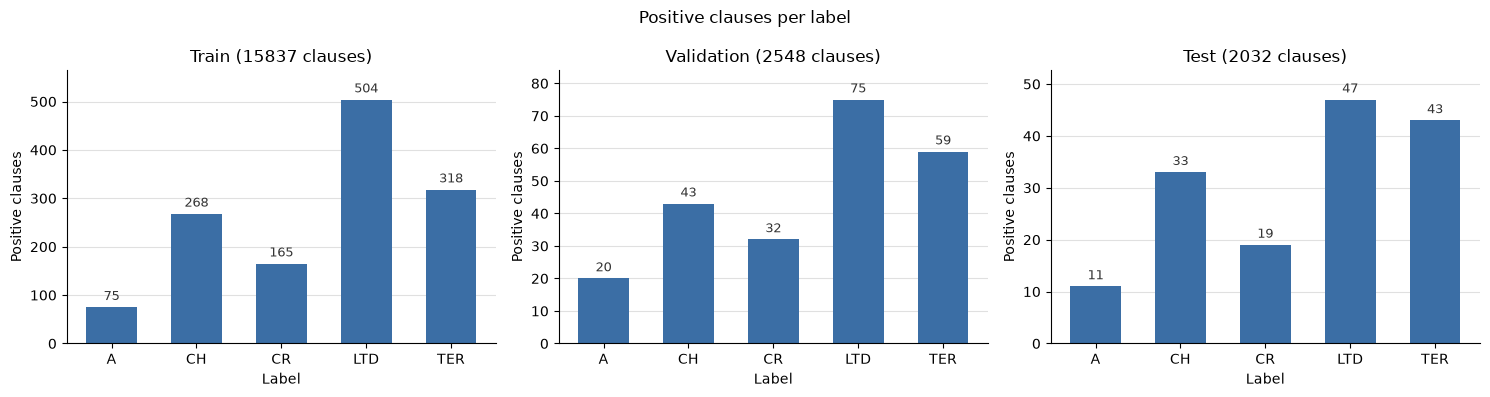

In [88]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, y) in zip(axes, (('Train', y_train), ('Validation', y_val), ('Test', y_test))):
    counts = y.sum(axis=0).astype(int)
    bars = ax.bar(label_cols, counts, width=0.6, color='#3b6ea5')
    ax.bar_label(bars, padding=3, fontsize=9, color='#333333')
    ax.set_title(f"{name} ({len(y)} clauses)")
    ax.set_xlabel('Label')
    ax.set_ylabel('Positive clauses')
    ax.margins(y=0.12)
    ax.grid(axis='y', color='#e0e0e0', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle('Positive clauses per label')
fig.tight_layout()
plt.show()

### Report

In [89]:
stats = {}
for name, y in (('train', y_train), ('validation', y_val), ('test', y_test)):
    n_labels = y.sum(axis=1)
    stats[name] = {
        'clauses': len(y),
        'positive clauses': int((n_labels >= 1).sum()),
        **{f'pos {label}': int(count) for label, count in zip(label_cols, y.sum(axis=0))},
        '0 labels': int((n_labels == 0).sum()),
        '1 label': int((n_labels == 1).sum()),
        '2+ labels': int((n_labels >= 2).sum()),
    }

stats_df = pd.DataFrame(stats).T
stats_df

,clauses,positive clauses,pos A,pos CH,pos CR,pos LTD,pos TER,0 labels,1 label,2+ labels
train,15837,1223,75,268,165,504,318,14614,1124,99
validation,2548,212,20,43,32,75,59,2336,195,17
test,2032,139,11,33,19,47,43,1893,127,12


As anticipated by the assignment, the corpus is **heavily imbalanced**: 92.3% of the training clauses carry no label.

## Task 2a - Data Cleaning
The data has already been tokenized, so the remaining tokenizer artifacts must be restored.

In [90]:
import re

import nltk
from nltk import pos_tag
from nltk.corpus import wordnet
from nltk.stem import WordNetLemmatizer

nltk.download('wordnet', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

ENUMERATOR = r"(?:\d+|[a-z]|[ivx]+)"
NUMBERING_RE = re.compile(
    rf"^(?:-l[rs]b- {ENUMERATOR} -r[rs]b-"
    rf"|{ENUMERATOR} -r[rs]b-"
    rf"|\d+(?:\.\d+)+\.?"
    rf"|\d+ [.°]"
    rf"|[•·●*-])\s+"
)
TOKEN_MAP = {
    '-lrb-': '(', '-rrb-': ')', '-lsb-': '[', '-rsb-': ']', '-lcb-': '{', '-rcb-': '}',
    '``': '"', "''": '"', '`': "'",
}
CLITICS = {"'s", "'re", "'ve", "'ll", "'d", "'m", "n't"}
SPECIAL_CHARS_RE = re.compile(r"[^a-z0-9\s.,;:!?()\[\]{}\"'/$%&@-]")

lemmatizer = WordNetLemmatizer()


def get_wordnet_key(tag: str) -> str | None:
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    return None


def strip_numbering(text: str) -> str:
    while (stripped := NUMBERING_RE.sub('', text, count=1)) != text:
        text = stripped
    return text


def lemmatize(tokens: list[str]) -> list[str]:
    lemmas = []
    for i, (word, tag) in enumerate(pos_tag(tokens)):
        key = get_wordnet_key(tag)
        before_negation = i + 1 < len(tokens) and tokens[i + 1] == "n't"
        lemmas.append(lemmatizer.lemmatize(word, key) if key and not before_negation else word)
    return lemmas


def reattach_clitics(tokens: list[str]) -> list[str]:
    merged = []
    for token in tokens:
        if token in CLITICS and merged:
            merged[-1] += token
        else:
            merged.append(token)
    return merged


def clean_text(text: str) -> str:
    text = strip_numbering(text)
    tokens = [TOKEN_MAP.get(token, token) for token in text.split()]
    tokens = reattach_clitics(lemmatize(tokens))
    text = SPECIAL_CHARS_RE.sub(' ', ' '.join(tokens))
    return ' '.join(text.split())


for df in (training_set, val_set, test_set):
    df['clean_text'] = df['text'].apply(clean_text)

In [91]:
examples = training_set['text'].str.match(r"^(?:-lrb- \w+ -rrb-|\d+\.\d+|[•·●*-] )|.*(?:n't|``)")
pd.set_option('display.max_colwidth', None)
training_set.loc[examples, ['text', 'clean_text']].sample(8, random_state=0)

,text,clean_text
14879,"our logo and the terms `` couchsurfing '' and `` couchsurfer '' , as well as other terms and visual elements that you might see throughout the couchsurfing services , are protected trademarks .","our logo and the term "" couchsurfing "" and "" couchsurfer "" , as well as other term and visual element that you might see throughout the couchsurfing service , be protect trademark ."
4772,2.1 we aim to deliver the product to you at the place of delivery requested by you in your order .,we aim to deliver the product to you at the place of delivery request by you in your order .
15564,you must choose an account name for your account which may also serve as the name for your graphical representation within each product -lrb- your `` avatar '' -rrb- .,"you must choose an account name for your account which may also serve as the name for your graphical representation within each product ( your "" avatar "" ) ."
2717,22.9 if you have any questions about these terms please email us .,if you have any question about these term please email us .
9640,"if you purchase or subscribe to such paid services , you agree to pay us the applicable fees -lrb- `` truecaller fees '' -rrb- and taxes in accordance with the applicable third party payment and billing terms , based on the platform you are using , which are incorporated herein by reference .","if you purchase or subscribe to such pay service , you agree to pay us the applicable fee ( "" truecaller fee "" ) and tax in accordance with the applicable third party payment and billing term , base on the platform you be use , which be incorporate herein by reference ."
10263,the service is provided by paradox on an `` as is '' and `` as available '' basis .,"the service be provide by paradox on an "" as be "" and "" as available "" basis ."
8300,"article r.211-5 : `` the information mentioned in sections 1 ° , 3 ° , 4 ° , 5 ° and 7 ° of article r. 2114 communicated to the traveller forms part of the contract and can only be modified under the conditions defined in article l. 211 - 9 . ''","article r.211-5 : "" the information mention in section 1 , 3 , 4 , 5 and 7 of article r. 2114 communicate to the traveller form part of the contract and can only be modify under the condition define in article l. 211 - 9 . """
4563,"4.8 your order remains valid as an offer until we issue our confirmation of order or , if earlier , when we receive your notice revoking your order .","your order remain valid as an offer until we issue our confirmation of order or , if early , when we receive your notice revoke your order ."


## Task 2b - Label Analysis
The training set is examined to choose the imbalance strategy used in Task 5.

### Positive Rate per Category

In [92]:
pos_rate = pd.Series(y_train.mean(axis=0), index=label_cols, name='positive rate')
(pos_rate * 100).round(2).to_frame('positive rate (%)')

,positive rate (%)
A,0.47
CH,1.69
CR,1.04
LTD,3.18
TER,2.01


### Co-occurrence

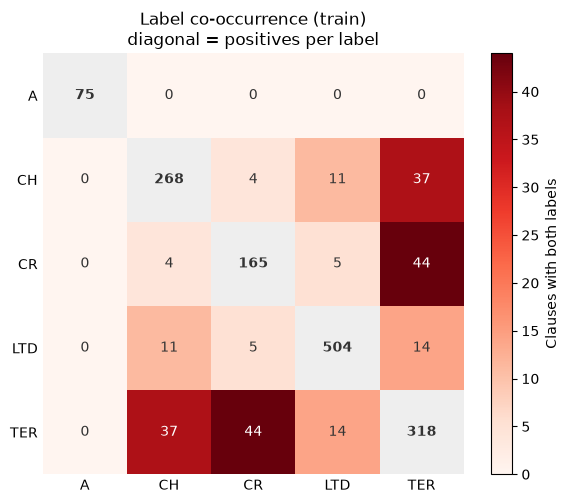

In [93]:
cooc = pd.DataFrame((y_train.T @ y_train).astype(int), index=label_cols, columns=label_cols)

off_diag = np.ma.masked_where(np.eye(len(label_cols), dtype=bool), cooc.to_numpy())
cmap = plt.get_cmap('Reds').copy()
cmap.set_bad('#eeeeee')

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(off_diag, cmap=cmap, vmin=0)

for i in range(len(label_cols)):
    for j in range(len(label_cols)):
        value = cooc.iat[i, j]
        dark_cell = i != j and value > off_diag.max() / 2
        ax.text(j, i, value, ha='center', va='center', fontsize=10,
                color='white' if dark_cell else '#333333', fontweight='bold' if i == j else 'normal')

ax.set_xticks(range(len(label_cols)), label_cols)
ax.set_yticks(range(len(label_cols)), label_cols)
ax.set_title('Label co-occurrence (train)\ndiagonal = positives per label')
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, label='Clauses with both labels')
fig.tight_layout()
plt.show()

The heatmap above highlights a strong imbalance across labels: `A` occurs only 75 times in the training set, less than half as often as `CR`, the second rarest. Moreover, `A` never co-occurs with any other label, so oversampling `A` clauses alone does not inflate the counts of other categories. Each `A` clause is therefore repeated 4 times in the training set only.

Positive rates are, however, low for every category. Therefore, in Task 5 the loss is also **reweighted** through the `pos_weight` argument of `BCEWithLogitsLoss`, with a separate weight for the positive class of each category, computed on the oversampled training set:
$$
    L_c = - [w_c y_c \log \hat{y}_c + (1-y_c) \log(1- \hat{y}_c)], \quad w_c = \frac{N_c^{neg}}{N_c^{pos}}
$$

Four observations motivate this choice:
- **An unweighted loss would be dominated by negatives**: predicting "no label" already reaches an accuracy of about 92% and a low binary cross-entropy. Weighting makes positive and negative samples contribute equally to the loss.
- **It matches the multi-label formulation**: each category is an independent binary decision with its own degree of imbalance.
- **It aligns training with the evaluation metric**: macro F1 weighs all five categories equally, so the rare ones cannot be sacrificed in favour of the frequent ones.
- **It covers every category**: oversampling treats only `A`, whereas reweighting acts on all five.

## Task 3 - Text Encoding
The cleaned text is encoded with `GloVe` embeddings. The vocabulary covers every training token, while validation and test OOV tokens are mapped to `<UNK>`. The OOV rate is reported for each split, since legal text contains domain-specific words that a general-purpose embedding model may not cover.

### Embedding
Dense embeddings need fewer parameters than sparse representations, which reduces the risk of overfitting, and generalise better to related words. The 100-dimensional `glove-wiki-gigaword` is used: since the Embedding layer is trainable, it holds |V| × d ≈ 40M parameters (120M with d = 300) for about 16k training clauses.

In [94]:
from collections import Counter

import gensim.downloader as gloader

glove = gloader.load('glove-wiki-gigaword-100')

PAD, UNK = '<PAD>', '<UNK>'
PAD_IDX, UNK_IDX = 0, 1

train_counts = Counter(token for text in training_set['clean_text'] for token in text.split())
train_oov = [token for token in train_counts if token not in glove.key_to_index]

idx_to_word = [PAD, UNK] + glove.index_to_key + train_oov
word_to_idx = {word: idx for idx, word in enumerate(idx_to_word)}

print(f"GloVe words: {len(glove.index_to_key)}, train tokens added: {len(train_oov)}, vocabulary size: {len(word_to_idx)}")

GloVe words: 400000, train tokens added: 1520, vocabulary size: 401522


### OOV Handling
- **GloVe words**: pre-trained GloVe vector.
- **Training tokens missing from GloVe**: mean of the GloVe vectors of their parts, obtained by detaching a trailing clitic (`don't` → `do` + `n't`) and splitting on `-` and `/` (`non-infringement` → `non` + `infringement`). Most of these tokens come from the clitic reattachment of Task 2a or are compounds of known words. Tokens with no part in GloVe (mostly brand names) get a random vector from U(-0.05, 0.05).
- **`<UNK>`**: fixed random vector from U(-0.05, 0.05), for validation and test tokens outside the vocabulary.
- **`<PAD>`**: zero vector.

In [95]:
def compose_vector(token: str) -> np.ndarray | None:
    clitic = next((c for c in CLITICS if token.endswith(c) and token != c), None)
    stem = token[:-len(clitic)] if clitic else token
    parts = re.split(r'[-/]', stem) + ([clitic] if clitic else [])
    vectors = [glove[part] for part in parts if part in glove.key_to_index]
    return np.mean(vectors, axis=0) if vectors else None


rng = np.random.default_rng(42)
embedding_dim = glove.vector_size

embedding_matrix = np.zeros((len(idx_to_word), embedding_dim), dtype=np.float32)
embedding_matrix[UNK_IDX] = rng.uniform(-0.05, 0.05, embedding_dim)
embedding_matrix[2:2 + len(glove.index_to_key)] = glove.vectors

composed = []
for token in train_oov:
    vector = compose_vector(token)
    if vector is None:
        vector = rng.uniform(-0.05, 0.05, embedding_dim)
    else:
        composed.append(token)
    embedding_matrix[word_to_idx[token]] = vector

print(f"Embedding matrix shape: {embedding_matrix.shape}")
print(f"Train OOV tokens: {len(train_oov)} -> composed from GloVe parts: {len(composed)}, random: {len(train_oov) - len(composed)}")

Embedding matrix shape: (401522, 100)
Train OOV tokens: 1520 -> composed from GloVe parts: 794, random: 726


In [96]:
print("Composition check: 5 closest GloVe words for each composed token\n")
for token in ["don't", "member's", "non-infringement", "you're"]:
    neighbours = glove.similar_by_vector(embedding_matrix[word_to_idx[token]], topn=5)
    print(f"{token:>18} -> {[word for word, _ in neighbours]}")

Composition check: 5 closest GloVe words for each composed token

             don't -> ['do', "n't", 'know', 'you', 'want']
          member's -> ["'s", 'member', 'the', 'one', 'whose']
  non-infringement -> ['infringement', 'non', 'violation', 'rights', 'copyright']
            you're -> ['you', "'re", "'ll", "n't", 'know']


Although the Embedding layer is trainable, `<UNK>` stays static: every training token is in the vocabulary and no training clause is empty after cleaning, so `<UNK>` never occurs in a training batch and receives no gradient.

In [97]:
def encode(text: str) -> list[int]:
    return [word_to_idx.get(token, UNK_IDX) for token in text.split()]


for df in (training_set, val_set, test_set):
    df['token_ids'] = df['clean_text'].apply(encode)

In [98]:
oov_report = {}
for name, df in (('train', training_set), ('validation', val_set), ('test', test_set)):
    counts = Counter(token for text in df['clean_text'] for token in text.split())
    if name == 'train':
        oov = [token for token in counts if token not in glove.key_to_index]
    else:
        oov = [token for token in counts if token not in word_to_idx]
    oov_report[name] = {
        'token types': len(counts),
        'OOV types': len(oov),
        'OOV types (%)': round(100 * len(oov) / len(counts), 2),
        'OOV occurrences (%)': round(100 * sum(counts[token] for token in oov) / counts.total(), 2),
    }

pd.DataFrame.from_dict(oov_report, orient='index')

,token types,OOV types,OOV types (%),OOV occurrences (%)
train,8228,1520,18.47,1.11
validation,3501,200,5.71,0.58
test,3346,156,4.66,0.81


The final vocabulary has 401,522 entries: `<PAD>`, `<UNK>`, the 400,000 GloVe words and 1,520 training tokens missing from GloVe.

Almost one training type in five is missing from GloVe, but these types cover only 1.1% of the occurrences; they are mostly brand names, reattached clitics and hyphenated compounds. The legal vocabulary, on the other hand, is largely covered. `<UNK>` tokens are below 1% of the occurrences in both validation and test, so their impact should be limited.

### Padding and Truncation
- **Dynamic padding**: each batch is padded with `<PAD>` (index 0) to its longest clause.
- **Truncation**: each clause keeps its first `MAX_LEN` tokens; `MAX_LEN` is chosen on the training set.
- **`padding_idx=0`**: the `<PAD>` vector stays zero and receives no gradient (equivalent to `mask_zero=True`).
- **Packing**: `pack_padded_sequence` makes the Bi-LSTM skip `<PAD>`, so the hidden states depend only on the real tokens.

In [99]:
train_lengths = training_set['token_ids'].str.len()
positive = y_train.any(axis=1)

length_report = {}
for name, lengths in (('all clauses', train_lengths), ('positive clauses', train_lengths[positive])):
    length_report[name] = {
        'mean': round(lengths.mean(), 1),
        'median': lengths.median(),
        'p95': lengths.quantile(0.95),
        'p99': lengths.quantile(0.99),
        'max': lengths.max(),
        **{f'> {n} tokens': int((lengths > n).sum()) for n in (64, 100, 128, 150)},
    }

pd.DataFrame.from_dict(length_report, orient='index')

,mean,median,p95,p99,max,> 64 tokens,> 100 tokens,> 128 tokens,> 150 tokens
all clauses,32.0,26.0,75.0,131.64,353,1221,335,169,97
positive clauses,44.0,33.0,109.8,200.00,353,204,75,43,30


Positive clauses are longer than average, so a short `MAX_LEN` would mostly cut the clauses to detect. `MAX_LEN = 150` (about the 99th percentile) truncates 97 training clauses (30 positive) and avoids very long sequences.

In [100]:
import torch
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset

MAX_LEN = 150


class ClauseDataset(Dataset):
    def __init__(self, token_ids: pd.Series, labels: np.ndarray):
        self.sequences = [torch.tensor((ids or [UNK_IDX])[:MAX_LEN]) for ids in token_ids]
        self.labels = torch.tensor(labels)

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        return self.sequences[idx], self.labels[idx]


def collate(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(seq) for seq in sequences])
    padded = pad_sequence(sequences, batch_first=True, padding_value=PAD_IDX)
    return padded, lengths, torch.stack(labels)


truncated = int((train_lengths > MAX_LEN).sum())
print(f"MAX_LEN = {MAX_LEN}: truncated train clauses {truncated} ({100 * truncated / len(train_lengths):.2f}%), "
      f"of which positive {int((train_lengths[positive] > MAX_LEN).sum())}")

padded, lengths, labels = collate([ClauseDataset(val_set['token_ids'], y_val)[i] for i in range(4)])
print(f"example batch: ids {tuple(padded.shape)}, lengths {lengths.tolist()}, targets {tuple(labels.shape)}")

MAX_LEN = 150: truncated train clauses 97 (0.61%), of which positive 30
example batch: ids (4, 91), lengths [91, 10, 27, 25], targets (4, 5)


## Task 4 - Model Definition

### Architecture
Two recurrent classifiers are defined, which differ only in depth: the **Baseline** is a Bidirectional LSTM with a Dense layer on top, and the **Stacked** model adds a second Bidirectional LSTM layer. Since a clause can be unfair under several categories at once, the solution does not adopt softmax, but rather outputs one independent score per category instead of a single choice among five classes.

Both models read the token ids of Task 3 through an Embedding layer initialized with the embedding matrix. Each clause is represented by the element-wise maximum of the hidden states of the last Bi-LSTM layer over all its tokens, which do not include `<PAD>`.

This encoding was compared with the concatenation of the final forward and backward states on the Baseline (see Additional Experiments): the maximum reaches a validation macro F1 of 0.546 ± 0.006 against 0.507 ± 0.015, and is better on all three seeds and all five categories. It adds no parameters, so the layers of the model do not change. The Stacked model uses the same encoding, without a separate comparison.

In [101]:
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence


class BiLSTMClassifier(nn.Module):
    def __init__(self, embedding_matrix: np.ndarray, hidden_size: int, num_layers: int, n_labels: int = len(label_cols),
                 freeze_embedding: bool = False):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(
            torch.tensor(embedding_matrix), freeze=freeze_embedding, padding_idx=PAD_IDX
        )
        self.lstm = nn.LSTM(embedding_matrix.shape[1], hidden_size, num_layers=num_layers,
                            batch_first=True, bidirectional=True)
        self.dense = nn.Linear(2 * hidden_size, n_labels)

    def forward(self, token_ids: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        packed = pack_padded_sequence(self.embedding(token_ids), lengths.cpu(),
                                      batch_first=True, enforce_sorted=False)
        outputs, _ = self.lstm(packed)
        states, _ = pad_packed_sequence(outputs, batch_first=True)
        padding = torch.arange(states.size(1), device=states.device) >= lengths.to(states.device).unsqueeze(1)
        return self.dense(states.masked_fill(padding.unsqueeze(-1), float('-inf')).max(dim=1).values)

### Baseline and Stacked
Both models use 128 hidden units per direction, so that the Dense layer receives a 256-dimensional vector. In the Stacked model, the second Bi-LSTM layer reads the concatenated outputs of the first one; every other component is the same.

In [102]:
HIDDEN_SIZE = 128
MODEL_LAYERS = {'Baseline': 1, 'Stacked': 2}

for name, num_layers in MODEL_LAYERS.items(): 
    model = BiLSTMClassifier(embedding_matrix, HIDDEN_SIZE, num_layers)
    with torch.no_grad():
        logits = model(padded, lengths)
    embedding_params = model.embedding.weight.numel()
    other_params = sum(p.numel() for p in model.parameters()) - embedding_params
    print(f"{name}: output {tuple(logits.shape)}, parameters excluding Embedding {other_params:,}, Embedding {embedding_params:,}")

Baseline: output (4, 5), parameters excluding Embedding 236,805, Embedding 40,152,200
Stacked: output (4, 5), parameters excluding Embedding 632,069, Embedding 40,152,200


### Baseline Graph
The diagram follows a batch of clauses through the Baseline, from token ids to one decision per category. In the shapes, `B` is the batch size and `T` the length of the longest clause in the batch, since both change from batch to batch; the other sizes are fixed: 100 for the GloVe vectors, 256 for the Bi-LSTM states (128 hidden units per direction) and 5 for the categories.

The Embedding layer turns each token id into its GloVe vector, and the Bi-LSTM reads the clause in both directions, so each token gets a state of size 256 that depends on its context. The element-wise maximum over the tokens, with `<PAD>` excluded, reduces the clause to a single vector of fixed size, and the Dense layer maps it to one score per category. The sigmoid and the thresholds are applied outside the model: during training the scores go straight into `BCEWithLogitsLoss`. The Stacked model only adds the dashed layer.

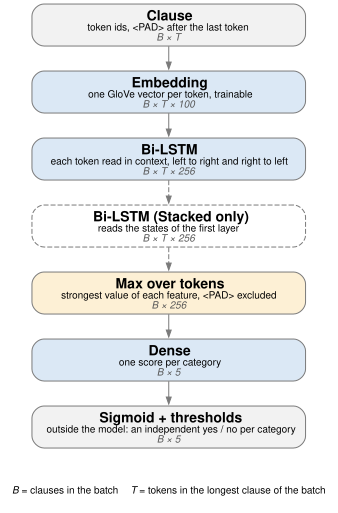

In [103]:
import graphviz

steps = [
    ('Clause', 'token ids, &lt;PAD&gt; after the last token', 'B × T', '#f2f2f2'),
    ('Embedding', 'one GloVe vector per token, trainable', 'B × T × 100', '#dbe8f5'),
    ('Bi-LSTM', 'each token read in context, left to right and right to left', 'B × T × 256', '#dbe8f5'),
    ('Bi-LSTM (Stacked only)', 'reads the states of the first layer', 'B × T × 256', '#ffffff'),
    ('Max over tokens', 'strongest value of each feature, &lt;PAD&gt; excluded', 'B × 256', '#fdf0d5'),
    ('Dense', 'one score per category', 'B × 5', '#dbe8f5'),
    ('Sigmoid + thresholds', 'outside the model: an independent yes / no per category', 'B × 5', '#f2f2f2'),
]

network_graph = graphviz.Digraph('Baseline', graph_attr={'ranksep': '0.35'},
                                 node_attr={'shape': 'box', 'fontname': 'Helvetica', 'width': '3.8', 'color': '#7a7a7a'},
                                 edge_attr={'color': '#7a7a7a', 'arrowsize': '0.7'})
for i, (title, text, shape, fill) in enumerate(steps):
    stacked_only = title.endswith('(Stacked only)')
    network_graph.node(str(i), fillcolor=fill, style='rounded,dashed,filled' if stacked_only else 'rounded,filled',
                       label=f'<<b>{title}</b><br/><font point-size="10">{text}</font><br/>'
                             f'<font point-size="10" color="#555555"><i>{shape}</i></font>>')
    if i:
        network_graph.edge(str(i - 1), str(i), style='dashed' if stacked_only or steps[i - 1][0].endswith('only)') else 'solid')
network_graph.node('legend', shape='plaintext', label='<<font point-size="10"><i>B</i> = clauses in the batch &#160;&#160; '
                                                      '<i>T</i> = tokens in the longest clause of the batch</font>>')
network_graph.edge(str(len(steps) - 1), 'legend', style='invis')
network_graph

## Task 5 - Training and Evaluation
Baseline and Stacked are trained with the imbalance strategy of Task 2b and evaluated on the validation and test sets. Every choice (best epoch, decision thresholds, best model) relies on the validation set only: test scores are just reported.

### Configuration
Each model is trained with 3 seeds for 20 epochs, on mini-batches of 64 clauses. The optimizer is Adam, which adapts the step of each parameter: `pos_weight` gives the categories very different gradient scales, so a single fixed step would need a costly search of the learning rate.

In [104]:
import time

SEEDS = [42, 1337, 2026]
EPOCHS = 20
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def set_seed(seed: int):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


print(f"Device: {DEVICE}")

Device: cuda


### Imbalance Strategy
`A` clauses are repeated `A_FACTOR = 4` times in the training set only, after the vocabulary has been built. `pos_weight` is then computed on the oversampled set, so the weight of `A` drops from about 210 to about 52.

Compared with no oversampling on the Baseline (see Additional Experiments), `A_FACTOR = 4` leaves the validation macro F1 unchanged (0.546 ± 0.006 against 0.547 ± 0.008 at threshold `0.5`) and raises the F1 of `A` (0.401 against 0.365), so it is kept for the rarest category.

In [105]:
from torch.utils.data import DataLoader

A_FACTOR = 4

a_clauses = training_set[training_set['A'] == 1]
train_resampled = pd.concat([training_set] + [a_clauses] * (A_FACTOR - 1), ignore_index=True)
y_resampled = train_resampled[label_cols].to_numpy(dtype=np.float32)

n_pos = y_resampled.sum(axis=0)
pos_weight = torch.tensor((len(y_resampled) - n_pos) / n_pos)

train_dataset = ClauseDataset(train_resampled['token_ids'], y_resampled)
val_loader = DataLoader(ClauseDataset(val_set['token_ids'], y_val), batch_size=256, collate_fn=collate)
test_loader = DataLoader(ClauseDataset(test_set['token_ids'], y_test), batch_size=256, collate_fn=collate)

print(f"Training clauses: {len(training_set)} -> {len(train_resampled)}")
print(f"pos_weight: { {label: round(weight, 1) for label, weight in zip(label_cols, pos_weight.tolist())} }")

Training clauses: 15837 -> 16062
pos_weight: {'A': 52.5, 'CH': 58.9, 'CR': 96.3, 'LTD': 30.9, 'TER': 49.5}


### Metrics and Threshold Tuning
Macro precision, recall and F1 average the five binary scores computed on the positive class. Per-category F1 is also reported, since the macro average hides the differences between categories.

For each category, the threshold is the value in {0.05, 0.10, ..., 0.95} that maximises F1 on the validation set. Validation scores with tuned thresholds are therefore optimistic, while test scores are not. With only 20 positive `A` clauses in validation the choice is noisy, so the thresholds are reported with their variability across seeds.

In [106]:
from sklearn.metrics import f1_score, precision_score, recall_score

THRESHOLD_GRID = np.arange(0.05, 0.96, 0.05)


def compute_metrics(y_true: np.ndarray, probs: np.ndarray, thresholds: float | np.ndarray = 0.5) -> dict:
    y_pred = (probs >= thresholds).astype(int)
    per_category = f1_score(y_true, y_pred, average=None, zero_division=0)
    return {
        'macro F1': per_category.mean(),
        'macro precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'macro recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
        **{f'F1 {label}': score for label, score in zip(label_cols, per_category)},
    }


def tune_thresholds(y_true: np.ndarray, probs: np.ndarray) -> np.ndarray:
    thresholds = []
    for c in range(y_true.shape[1]):
        scores = [f1_score(y_true[:, c], probs[:, c] >= t, zero_division=0) for t in THRESHOLD_GRID]
        thresholds.append(THRESHOLD_GRID[np.argmax(scores)])
    return np.array(thresholds)

### Training Loop
After each epoch the model is evaluated on the validation set, and the weights of the epoch with the highest macro F1 (threshold 0.5) are kept. The thresholds are then tuned on those weights, and the test set is used only at this point.

In [107]:
@torch.no_grad()
def predict_proba(model: nn.Module, loader: DataLoader) -> np.ndarray:
    model.eval()
    return np.concatenate([torch.sigmoid(model(ids.to(DEVICE), lengths)).cpu().numpy() for ids, lengths, _ in loader])


def train_model(num_layers: int, seed: int) -> dict:
    set_seed(seed)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate,
                              generator=torch.Generator().manual_seed(seed))

    model = BiLSTMClassifier(embedding_matrix, HIDDEN_SIZE, num_layers).to(DEVICE)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(DEVICE))
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    best_f1, best_epoch, best_state = -1.0, 0, None
    history = []
    for epoch in range(1, EPOCHS + 1):
        model.train()
        epoch_loss = 0.0
        for ids, lengths, labels in train_loader:
            optimizer.zero_grad()
            loss = loss_fn(model(ids.to(DEVICE), lengths), labels.to(DEVICE))
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * len(labels)

        val_f1 = compute_metrics(y_val, predict_proba(model, val_loader))['macro F1']
        history.append({'epoch': epoch, 'train_loss': epoch_loss / len(train_dataset), 'val_macro_f1': val_f1})
        if val_f1 > best_f1:
            best_f1, best_epoch = val_f1, epoch
            best_state = {key: value.cpu().clone() for key, value in model.state_dict().items()}

    model.load_state_dict(best_state)
    val_probs = predict_proba(model, val_loader)
    return {
        'seed': seed,
        'best_epoch': best_epoch,
        'history': history,
        'val_probs': val_probs,
        'test_probs': predict_proba(model, test_loader),
        'thresholds': tune_thresholds(y_val, val_probs),
    }

### Baseline and Stacked Runs
Probabilities, thresholds and curves of every run are saved to a file for the following sections. With `TRAIN_MODELS = False` the runs are reloaded instead of being trained again; the log below comes from the full training.

In [108]:
from tqdm import tqdm

TRAIN_MODELS = False
RUNS_FILE = Path.cwd() / 'Experiments' / 'results' / 'task5_runs.pkl'

if TRAIN_MODELS:
    runs = {name: [] for name in MODEL_LAYERS}
    configs = [(name, num_layers, seed) for name, num_layers in MODEL_LAYERS.items() for seed in SEEDS]
    for name, num_layers, seed in tqdm(configs, desc='Runs'):
        start = time.time()
        run = train_model(num_layers, seed)
        runs[name].append(run)
        tqdm.write(f"{name} | seed {seed} | best epoch {run['best_epoch']:2d} | "
                   f"val macro F1 {run['history'][run['best_epoch'] - 1]['val_macro_f1']:.4f} | {time.time() - start:.0f} s")
    RUNS_FILE.parent.mkdir(parents=True, exist_ok=True)
    pd.to_pickle(runs, RUNS_FILE)
else:
    runs = pd.read_pickle(RUNS_FILE)

### Results
The tables below show that tuned thresholds improve macro F1, mainly by raising precision at the cost of a lower macro recall. The difference in precision is wide: on the test set, the largest gain is on the Baseline, where the tuned thresholds increase the precision by $\approx 0.090$, against $\approx 0.048$ on the Stacked model.

Scores differ widely across categories. `A` is last on both splits, possibly because it has the fewest positives, although this link has not been proven. On the other hand, `CH` is the least stable category among the five: on the Baseline with tuned thresholds, it moves from fourth in validation to first in test. This large gap exceeds the variability across seeds and may reflect differences between splits.

The thresholds are tuned on the validation set, so the scores on that set are considered optimistic. However, the table below shows that test scores are higher than validation scores, which may reflect a difference in the splits. The difference also exists with the fixed `0.5` threshold, so it does not come from threshold tuning. The share of positive clauses does not explain it either, since this share is lower on the test set in all five categories.

The tuned thresholds are often unstable across seeds, yet their means all exceed `0.5`, which is consistent with `pos_weight` pushing probabilities upwards. The lowest means are Baseline `LTD` and Stacked `CR`, both at 0.533, but they also have the highest standard deviation of their model, so the mean describes individual seeds poorly. The instability cannot be attributed to the category alone: `CR` is stable on the Baseline while highly unstable on the Stacked model (standard deviation 0.029 vs 0.362). F1 can be more stable than the thresholds: Baseline `LTD` has a threshold standard deviation of 0.306, but a validation F1 standard deviation of 0.009. A single threshold value therefore means little on its own, since each threshold applies to a specific model and seed.

In [109]:
def mean_std(scores: pd.DataFrame) -> pd.Series:
    return scores.mean().map('{:.3f}'.format) + ' ± ' + scores.std().map('{:.3f}'.format)


results = {}
for name, model_runs in runs.items():
    for split, y_true, key in (('validation', y_val, 'val_probs'), ('test', y_test, 'test_probs')):
        at_half = [compute_metrics(y_true, run[key]) for run in model_runs]
        tuned = [compute_metrics(y_true, run[key], run['thresholds']) for run in model_runs]
        results[(name, split, '0.5')] = mean_std(pd.DataFrame(at_half))
        results[(name, split, 'tuned')] = mean_std(pd.DataFrame(tuned))

results_table = pd.DataFrame(results).T.rename_axis(['model', 'split', 'threshold'])
thresholds_table = pd.DataFrame({
    name: mean_std(pd.DataFrame([run['thresholds'] for run in model_runs], columns=label_cols))
    for name, model_runs in runs.items()
}).T.rename_axis('tuned threshold')

display(results_table)
display(thresholds_table)

macro F1 macro precision   macro recall  \
model    split      threshold                                                 
Baseline validation 0.5        0.546 ± 0.006   0.495 ± 0.008  0.620 ± 0.025   
                    tuned      0.593 ± 0.007   0.615 ± 0.014  0.596 ± 0.027   
         test       0.5        0.618 ± 0.002   0.544 ± 0.015  0.725 ± 0.019   
                    tuned      0.649 ± 0.014   0.634 ± 0.017  0.681 ± 0.022   
Stacked  validation 0.5        0.547 ± 0.017   0.480 ± 0.041  0.659 ± 0.039   
                    tuned      0.574 ± 0.016   0.547 ± 0.045  0.625 ± 0.025   
         test       0.5        0.604 ± 0.029   0.517 ± 0.061  0.746 ± 0.050   
                    tuned      0.612 ± 0.025   0.565 ± 0.062  0.699 ± 0.053   

                                        F1 A          F1 CH          F1 CR  \
model    split      threshold                                                
Baseline validation 0.5        0.401 ± 0.042  0.556 ± 0.043  0.562 ± 0.032   
                    tuned      0.471 ± 0.005  0.594 ± 0.022  0.643 ± 0.021   
         test       0.5        0.471 ± 0.050  0.725 ± 0.015  0.594 ± 0.039   
                    tuned      0.538 ± 0.014  0.755 ± 0.014  0.631 ± 0.032   
Stacked  validation 0.5        0.410 ± 0.053  0.533 ± 0.051  0.589 ± 0.020   
                    tuned      0.440 ± 0.035  0.555 ± 0.052  0.623 ± 0.004   
         test       0.5        0.513 ± 0.012  0.654 ± 0.060  0.599 ± 0.076   
                    tuned      0.517 ± 0.015  0.685 ± 0.050  0.568 ± 0.086   

                                      F1 LTD         F1 TER  
model    split      threshold                                
Baseline validation 0.5        0.626 ± 0.010  0.582 ± 0.019  
                    tuned      0.644 ± 0.009  0.616 ± 0.022  
         test       0.5        0.624 ± 0.020  0.676 ± 0.011  
                    tuned      0.635 ± 0.027  0.686 ± 0.017  
Stacked  validation 0.5        0.622 ± 0.007  0.580 ± 0.016  
                    tuned      0.646 ± 0.006  0.606 ± 0.035  
         test       0.5        0.599 ± 0.002  0.656 ± 0.010  
                    tuned      0.614 ± 0.015  0.678 ± 0.049

,A,CH,CR,LTD,TER
tuned threshold,,,,,
Baseline,0.850 ± 0.173,0.733 ± 0.202,0.883 ± 0.029,0.533 ± 0.306,0.867 ± 0.076
Stacked,0.700 ± 0.180,0.783 ± 0.126,0.533 ± 0.362,0.667 ± 0.231,0.917 ± 0.058


### Learning Curves
The training loss of the two models almost overlaps: it falls from about 0.8 at epoch 1 to about 0.02–0.03 at epoch 20. The validation macro F1 (threshold 0.5) rises from about 0.30 to a maximum of 0.542 on the mean curve of both models, reached at epoch 16 by the Baseline and at epoch 12 by the Stacked model.

Both models overfit. A repeated run of the same training (`Task5_overfitting_check.ipynb`, with the same best epochs and scores), which also logs the validation loss and the macro F1 on the training clauses, shows it directly:
- the validation loss reaches its minimum at epoch 2 or 3 and then grows about fivefold by epoch 20 (Baseline: from 0.47 to 2.36), while the training loss keeps falling;
- at the best epoch the training macro F1 is 0.90 for the Baseline and 0.86 for the Stacked model, against 0.55 on validation.

The validation F1 keeps growing for several epochs after the validation loss has started to rise. This is consistent with the model becoming more and more confident on the clauses it gets wrong, which raises the loss, while the decisions at threshold 0.5 still improve. The Stacked model overfits more: from its best epoch to epoch 20 its validation F1 falls on all three seeds (0.056 on average), against 0.013 for the Baseline. This is consistent with its larger number of parameters (632,069 against 236,805, Embedding excluded) trained on the same data.

At epoch 19 the F1 drops in both models: in the Baseline one seed falls to 0.361 and recovers at epoch 20, while in the Stacked model all three seeds drop. Since the weights of each seed come from its best epoch on validation, the late epochs do not enter the results.

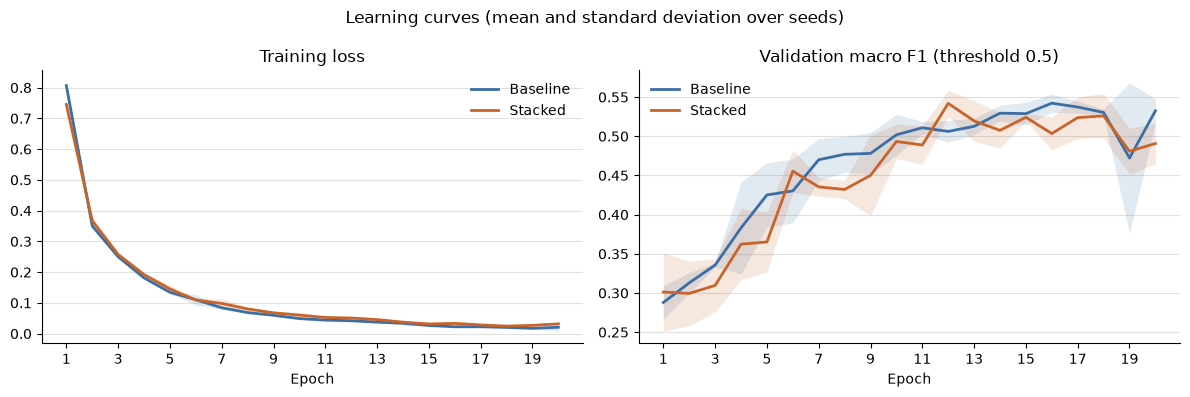

In [110]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = {'Baseline': '#3b6ea5', 'Stacked': '#c8642a'}

for ax, (metric, title) in zip(axes, (('train_loss', 'Training loss'), ('val_macro_f1', 'Validation macro F1 (threshold 0.5)'))):
    for name, model_runs in runs.items():
        curves = np.array([[step[metric] for step in run['history']] for run in model_runs])
        epochs = np.arange(1, curves.shape[1] + 1)
        ax.plot(epochs, curves.mean(axis=0), color=colors[name], linewidth=2, label=name)
        ax.fill_between(epochs, curves.mean(axis=0) - curves.std(axis=0, ddof=1), curves.mean(axis=0) + curves.std(axis=0, ddof=1),
                        color=colors[name], alpha=0.15, linewidth=0)
    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.set_xticks(epochs[::2])
    ax.grid(axis='y', color='#e0e0e0', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False)

fig.suptitle('Learning curves (mean and standard deviation over seeds)')
fig.tight_layout()
plt.show()

### Model Selection
The Baseline is selected, since it reaches a validation macro F1 of 0.593 ± 0.007 with tuned thresholds, against 0.574 ± 0.016 for the Stacked model. The advantage is small, as the two models are tied at threshold `0.5` (0.546 ± 0.006 against 0.547 ± 0.017), but the Baseline is also more stable across seeds and has fewer parameters.

In [111]:
val_macro_f1 = {
    name: np.mean([compute_metrics(y_val, run['val_probs'], run['thresholds'])['macro F1'] for run in model_runs])
    for name, model_runs in runs.items()
}
best_model = max(val_macro_f1, key=val_macro_f1.get)

print({name: round(float(score), 4) for name, score in val_macro_f1.items()})
print(f"Best model on validation macro F1: {best_model}") 

{'Baseline': 0.5933, 'Stacked': 0.5738}
Best model on validation macro F1: Baseline


## Task 6 - Transformers
LEGAL-BERT (`nlpaueb/legal-bert-base-uncased`) is a BERT-base encoder pre-trained on legal text (legislation, court
cases, contracts). It is fine-tuned end to end with a classification head on the `[CLS]` representation. Since the task
is multi-label, the head outputs 5 logits, each passed through an independent sigmoid, and the loss is
`BCEWithLogitsLoss`, as for the LSTM models.


### Tokenizer and Model

In [112]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

BERT_NAME = 'nlpaueb/legal-bert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)


def load_bert():
    return AutoModelForSequenceClassification.from_pretrained(
        BERT_NAME, problem_type='multi_label_classification',
        id2label=dict(enumerate(label_cols)), label2id={label: i for i, label in enumerate(label_cols)},
    )


print(tokenizer.tokenize(training_set['text'].iloc[5]))


['some', 'of', 'our', 'website', '##s', 'connect', 'you', 'with', 'links', ',', 'app', '##s', 'or', 'add', '-', 'on', '##s', 'that', 'are', 'provided', 'by', 'other', 'parties', 'and', 'are', 'subject', 'to', 'separate', 'terms', '.']


### Dataset Preprocessing
It is possible to use `bert_text`, the original `text` with only numbering removed, brackets and quotes restored and clitics reattached, since `WordPiece` cuts rare words into subwords. Lemmatisation can be avoided, as the tokenizer natively handles inflection (e.g. `website ##s`). `BERT_MAX_LEN=256` is adopted as it only truncates 14 training clauses, of which only 4 are positive, making the effects negligible. Moreover, `WordPiece` sequences are longer since subwords take more spots, so the previous `MAX_LEN=150` from Task 3 cannot be used here as it would cut more tokens. From Task 2a, **POS tag lemmatisation** is therefore discarded and special characters are not removed, since the vocabulary covers most of them. The model is `uncased` and the tokenizer automatically lowercases all characters. Labels are `float` vectors of size 5.

In [113]:
BERT_MAX_LEN=256

def bert_text(text: str) -> str:
    tokens = [TOKEN_MAP.get(token,token) for token in strip_numbering(text).split()]
    return ' '.join(reattach_clitics(tokens))


for df in (training_set, val_set, test_set):
    df['bert_text'] = df['text'].apply(bert_text)



class BertClauseDataset(Dataset):
    def __init__(self, texts: pd.Series, labels: np.ndarray):
        self.encodings = tokenizer(list(texts), truncation=True, max_length=BERT_MAX_LEN)
        self.labels = torch.tensor(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return {**{key: values[index] for key, values in self.encodings.items()}, 'labels': self.labels[index]}


def bert_collate(batch):
    labels = torch.stack([item.pop('labels') for item in batch])
    return {**tokenizer.pad(batch, return_tensors='pt',), 'labels' : labels}

bert_train_resampled = pd.concat([training_set] + [training_set[training_set['A'] == 1]] * (A_FACTOR - 1), ignore_index= True)
y_bert_train = bert_train_resampled[label_cols].to_numpy(dtype=np.float32)

bert_train = BertClauseDataset(bert_train_resampled['bert_text'], y_bert_train)
bert_val = BertClauseDataset(val_set['bert_text'], y_val)
bert_test = BertClauseDataset(test_set['bert_text'], y_test)

bert_lengths = pd.Series([len(ids) for ids in tokenizer(list(training_set['bert_text']))['input_ids']])
print(f"WordPiece length: mean {bert_lengths.mean():.1f}, p99 {bert_lengths.quantile(0.99):.0f}, max {bert_lengths.max()}")
print(f"BERT_MAX_LEN = {BERT_MAX_LEN}: truncated train clauses {int((bert_lengths > BERT_MAX_LEN).sum())}, "
      f"of which positive {int((bert_lengths[positive] > BERT_MAX_LEN).sum())}")


WordPiece length: mean 37.3, p99 148, max 370
BERT_MAX_LEN = 256: truncated train clauses 14, of which positive 4


In [114]:
def unk_stats(sequences: list[list[int]], unk_id: int) -> dict:
    total = sum(len(ids) for ids in sequences)
    unk = sum(ids.count(unk_id) for ids in sequences)
    return {'tokens': total, 'unknown tokens': unk, 'unknown tokens (%)': round(100 * unk / total, 2),
            'clauses with unknown tokens': sum(unk_id in ids for ids in sequences)}


unk_report = {}
for split, df in (('train', training_set), ('validation', val_set), ('test', test_set)):
    bert_ids = tokenizer(list(df['bert_text']), add_special_tokens=False)['input_ids']
    unk_report[('Baseline', split)] = unk_stats(list(df['token_ids']), UNK_IDX)
    unk_report[('LEGAL-BERT', split)] = unk_stats(bert_ids, tokenizer.unk_token_id)

unk_report = pd.DataFrame(unk_report).T.rename_axis(['model', 'split'])
unk_report

,,tokens,unknown tokens,unknown tokens (%),clauses with unknown tokens
model,split,,,,
Baseline,train,506541.0,0.0,0.00,0.0
LEGAL-BERT,train,559635.0,54.0,0.01,42.0
Baseline,validation,79433.0,464.0,0.58,341.0
LEGAL-BERT,validation,89013.0,15.0,0.02,11.0
Baseline,test,68163.0,552.0,0.81,400.0
LEGAL-BERT,test,75022.0,9.0,0.01,6.0


### Training
As in Task 5, the positive `A` clauses are oversampled by `A_FACTOR`, due to their rareness in the training dataset. `pos_weight` is also readopted so that a comparison with the LSTM can be performed in the same condition; it is passed to the Trainer using `compute_loss_func` as the standard uses BCE without weights. Thresholds are tuned only on the validation split. 

Trainer arguments reflect BERT fine-tuning convention (Devlin et al. 2018):
- `lr = 2e-5`: is considerably lower than the 1e-3 adopted for the LSTM, as the model is pretrained
- `linear warmup` on the first tenth of the steps in order to stabilise the start when the randomly initialized classification head produces large gradients
- `weight_decay=0.01`, which can be introduced as the constraint on `<UNK>` is only valid on the GloVe embedding
- `batch at 16 for 4 epochs`
- `fp16` to reduce VRAM and time

Epoch selection and seeds follow Task 5 (best validation macro F1 at threshold 0.5, seeds 42, 1337 and 2026), so that the comparison with the LSTM models is as neutral as possible.

The `LOAD REPORT` printed by `from_pretrained` is expected: `UNEXPECTED` keys are the discarded pre-training heads, `MISSING` keys are the new classification head, randomly initialized and trained during fine-tuning.

In [115]:
import shutil

from transformers import Trainer, TrainingArguments

BERT_EPOCHS = 4
TRAIN_BERT = False
BERT_RUNS_FILE = Path.cwd() / 'Experiments' / 'results' / 'task6_runs.pkl'
BERT_DIR = Path.cwd() / 'Experiments' / 'legalbert'

n_pos = y_bert_train.sum(axis=0)
bert_pos_weight= torch.tensor((len(y_bert_train) - n_pos)/ n_pos)

def weighted_bce(outputs, labels, num_items_in_batch=None):
    logits = outputs.logits
    return nn.functional.binary_cross_entropy_with_logits(logits, labels.to(logits.dtype), pos_weight=bert_pos_weight.to(logits.device))

def trainer_metrics(eval_pred) -> dict:
    probs = torch.sigmoid(torch.tensor(eval_pred.predictions)).numpy()
    return{'macro_f1' : compute_metrics(eval_pred.label_ids, probs)['macro F1']}

def train_bert(seed: int) -> dict:
    args = TrainingArguments(
        output_dir=str(BERT_DIR / f'seed_{seed}'), seed=seed, num_train_epochs=BERT_EPOCHS,
        learning_rate=2e-5, warmup_steps=0.1, weight_decay=0.01,
        per_device_train_batch_size = 16, per_device_eval_batch_size=64,
        fp16 = True,
        eval_strategy='epoch', save_strategy='epoch', logging_strategy='epoch',
        load_best_model_at_end=True, metric_for_best_model='macro_f1',
        save_total_limit=1, save_only_model=True, report_to='none' 
    )

    trainer = Trainer(model_init=load_bert, args=args, train_dataset=bert_train, eval_dataset=bert_val, data_collator=bert_collate, compute_loss_func=weighted_bce, compute_metrics=trainer_metrics)


    ###############
    trainer.train()
    ###############
     
    def predict(dataset):
        return torch.sigmoid(torch.tensor(trainer.predict(dataset).predictions)).numpy()

    val_probs = predict(bert_val)
    history = [ entry for entry in trainer.state.log_history if 'eval_macro_f1' in entry]

    return{
        'seed': seed,
        'best_epoch': int(round(max(history, key=lambda e: e['eval_macro_f1'])['epoch'])),
        'history' : history,
        'val_probs' : val_probs,
        'test_probs': predict(bert_test),
        'thresholds': tune_thresholds(y_val, val_probs) 
    }


if TRAIN_BERT:
    bert_runs = []
    for seed in SEEDS:
        start = time.time()
        bert_runs.append(train_bert(seed))
        print(f"LEGAL-BERT | seed {seed} | best epoch {bert_runs[-1]['best_epoch']} | {time.time() - start:.0f} s")
    pd.to_pickle({'LEGAL-BERT': bert_runs}, BERT_RUNS_FILE)
    shutil.rmtree(BERT_DIR, ignore_errors=True)
else:
    bert_runs = pd.read_pickle(BERT_RUNS_FILE)['LEGAL-BERT']

    
    

In [ ]:
all_runs = {**runs, 'LEGAL-BERT': bert_runs}

comparison = {}
for name, model_runs in all_runs.items():
    for split, y_true, key in (('validation', y_val, 'val_probs'), ('test', y_test, 'test_probs')):
        comparison[(name, split, '0.5')] = mean_std(pd.DataFrame([compute_metrics(y_true, run[key]) for run in model_runs]))
        comparison[(name, split, 'tuned')] = mean_std(pd.DataFrame(
            [compute_metrics(y_true, run[key], run['thresholds']) for run in model_runs]))

display(pd.DataFrame(comparison).T.rename_axis(['model', 'split', 'threshold']))
display(pd.DataFrame({
    'LEGAL-BERT': mean_std(pd.DataFrame([run['thresholds'] for run in bert_runs], columns=label_cols))
}).T.rename_axis('tuned threshold'))
print({run['seed']: run['best_epoch'] for run in bert_runs})


macro F1 macro precision   macro recall  \
model      split      threshold                                                 
Baseline   validation 0.5        0.546 ± 0.006   0.495 ± 0.008  0.620 ± 0.025   
                      tuned      0.593 ± 0.007   0.615 ± 0.014  0.596 ± 0.027   
           test       0.5        0.618 ± 0.002   0.544 ± 0.015  0.725 ± 0.019   
                      tuned      0.649 ± 0.014   0.634 ± 0.017  0.681 ± 0.022   
Stacked    validation 0.5        0.547 ± 0.017   0.480 ± 0.041  0.659 ± 0.039   
                      tuned      0.574 ± 0.016   0.547 ± 0.045  0.625 ± 0.025   
           test       0.5        0.604 ± 0.029   0.517 ± 0.061  0.746 ± 0.050   
                      tuned      0.612 ± 0.025   0.565 ± 0.062  0.699 ± 0.053   
LEGAL-BERT validation 0.5        0.646 ± 0.012   0.600 ± 0.022  0.705 ± 0.019   
                      tuned      0.664 ± 0.008   0.644 ± 0.024  0.691 ± 0.016   
           test       0.5        0.698 ± 0.017   0.631 ± 0.035  0.788 ± 0.017   
                      tuned      0.704 ± 0.001   0.652 ± 0.015  0.771 ± 0.026   

                                          F1 A          F1 CH          F1 CR  \
model      split      threshold                                                
Baseline   validation 0.5        0.401 ± 0.042  0.556 ± 0.043  0.562 ± 0.032   
                      tuned      0.471 ± 0.005  0.594 ± 0.022  0.643 ± 0.021   
           test       0.5        0.471 ± 0.050  0.725 ± 0.015  0.594 ± 0.039   
                      tuned      0.538 ± 0.014  0.755 ± 0.014  0.631 ± 0.032   
Stacked    validation 0.5        0.410 ± 0.053  0.533 ± 0.051  0.589 ± 0.020   
                      tuned      0.440 ± 0.035  0.555 ± 0.052  0.623 ± 0.004   
           test       0.5        0.513 ± 0.012  0.654 ± 0.060  0.599 ± 0.076   
                      tuned      0.517 ± 0.015  0.685 ± 0.050  0.568 ± 0.086   
LEGAL-BERT validation 0.5        0.485 ± 0.056  0.630 ± 0.012  0.721 ± 0.032   
                      tuned      0.496 ± 0.050  0.646 ± 0.018  0.754 ± 0.000   
           test       0.5        0.670 ± 0.056  0.829 ± 0.022  0.622 ± 0.039   
                      tuned      0.632 ± 0.030  0.867 ± 0.028  0.628 ± 0.026   

                                        F1 LTD         F1 TER  
model      split      threshold                                
Baseline   validation 0.5        0.626 ± 0.010  0.582 ± 0.019  
                      tuned      0.644 ± 0.009  0.616 ± 0.022  
           test       0.5        0.624 ± 0.020  0.676 ± 0.011  
                      tuned      0.635 ± 0.027  0.686 ± 0.017  
Stacked    validation 0.5        0.622 ± 0.007  0.580 ± 0.016  
                      tuned      0.646 ± 0.006  0.606 ± 0.035  
           test       0.5        0.599 ± 0.002  0.656 ± 0.010  
                      tuned      0.614 ± 0.015  0.678 ± 0.049  
LEGAL-BERT validation 0.5        0.706 ± 0.023  0.689 ± 0.013  
                      tuned      0.716 ± 0.013  0.706 ± 0.009  
           test       0.5        0.642 ± 0.015  0.728 ± 0.027  
                      tuned      0.653 ± 0.012  0.740 ± 0.019

,A,CH,CR,LTD,TER
tuned threshold,,,,,
LEGAL-BERT,0.367 ± 0.333,0.783 ± 0.202,0.717 ± 0.104,0.600 ± 0.180,0.667 ± 0.115


{42: 4, 1337: 4, 2026: 3}


### Evaluation
LEGAL-BERT is evaluated with the same metrics and protocol as the Baseline and Stacked models of Task 5; the table above reports the full comparison.

The fine-tuned model reaches a validation macro F1 of 0.664 ± 0.008 with tuned thresholds, against 0.593 ± 0.007 for the Baseline, falling in the 60-75 range expected for the model. The gain is also visible on the test set (0.704 ± 0.001 vs 0.649 ± 0.014 for the Baseline), showing that the gap is well beyond the variability across seeds.

On the validation set the gain covers all five categories, while on the test set it mainly arises from `CH`, `A` and `TER`, suggesting that the advantage that comes from pre-training is not homogeneous across categories.

Tuned thresholds add little: +0.018 on validation and +0.006 on test, against +0.047 and +0.031 for the Baseline. LEGAL-BERT is therefore already well calibrated around `0.5`. The threshold of `A` remains the most unstable (0.367 ± 0.333 across seeds).

The best epoch is 4, 4 and 3, and for two seeds the validation F1 is still rising at the last epoch, so 4 epochs may stop training early. The validation loss grows from the second epoch while F1 keeps improving, so the model becomes overconfident on its errors, and `pos_weight` amplifies the effect; therefore the best epoch is selected on the F1 score instead of the loss.

As in Task 5, test scores exceed validation scores. The difference also exists with the fixed `0.5` threshold (0.698 vs 0.646), so it does not come from threshold tuning and is consistent with the difference between the splits observed for the LSTM models.


## Task 7 - Error Analysis
Among the experiment performed in task 5, the best model found was the `Baseline with tuned thresholds` and will be considered in the following observation. 

Lets consider the confusion matrix of the five categories, for each model:

### F1 Score

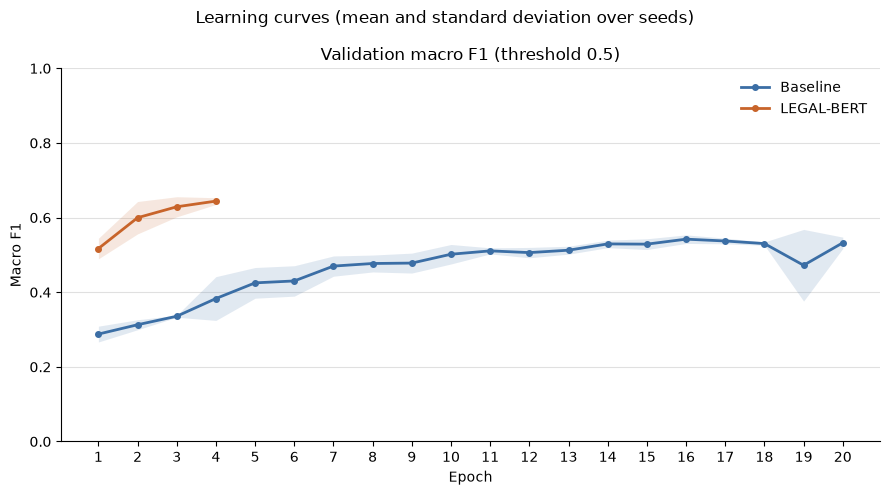

In [117]:
model_runs = {
    'Baseline': runs['Baseline'],
    'LEGAL-BERT': bert_runs
}

colors = {
    'Baseline': '#3b6ea5',
    'LEGAL-BERT': '#c8642a'
}

fig, ax = plt.subplots(figsize=(9, 5))

for name, model_history in model_runs.items():

    metric = 'val_macro_f1' if name == 'Baseline' else 'eval_macro_f1'

    curves = np.array([
        [step[metric] for step in run['history']]
        for run in model_history
    ])

    epochs = np.arange(1, curves.shape[1] + 1)

    mean = curves.mean(axis=0)
    std = curves.std(axis=0, ddof=1)

    ax.plot(
        epochs, mean,
        color=colors[name],
        linewidth=2,
        marker='o',
        markersize=4,
        label=name
    )

    ax.fill_between(
        epochs,
        mean - std,
        mean + std,
        color=colors[name],
        alpha=0.15,
        linewidth=0
    )

ax.set_title('Validation macro F1 (threshold 0.5)')
ax.set_xlabel('Epoch')
ax.set_ylabel('Macro F1')
ax.set_xticks(np.arange(1, 21))
ax.set_ylim(0, 1)

ax.grid(axis='y', color='#e0e0e0', linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)

fig.suptitle('Learning curves (mean and standard deviation over seeds)')
fig.tight_layout()
plt.show()

The F1 score highlight the visible standard deviation between seed. which are index of instability between seeds. The high value arise from the limnited number of positive clause among the dataset and make the threshold tuning unstable. In particular, for the raraest class `A`, the thrashold exhibit a great deviation (0.850 ± 0.173)

### Confusion Matrices

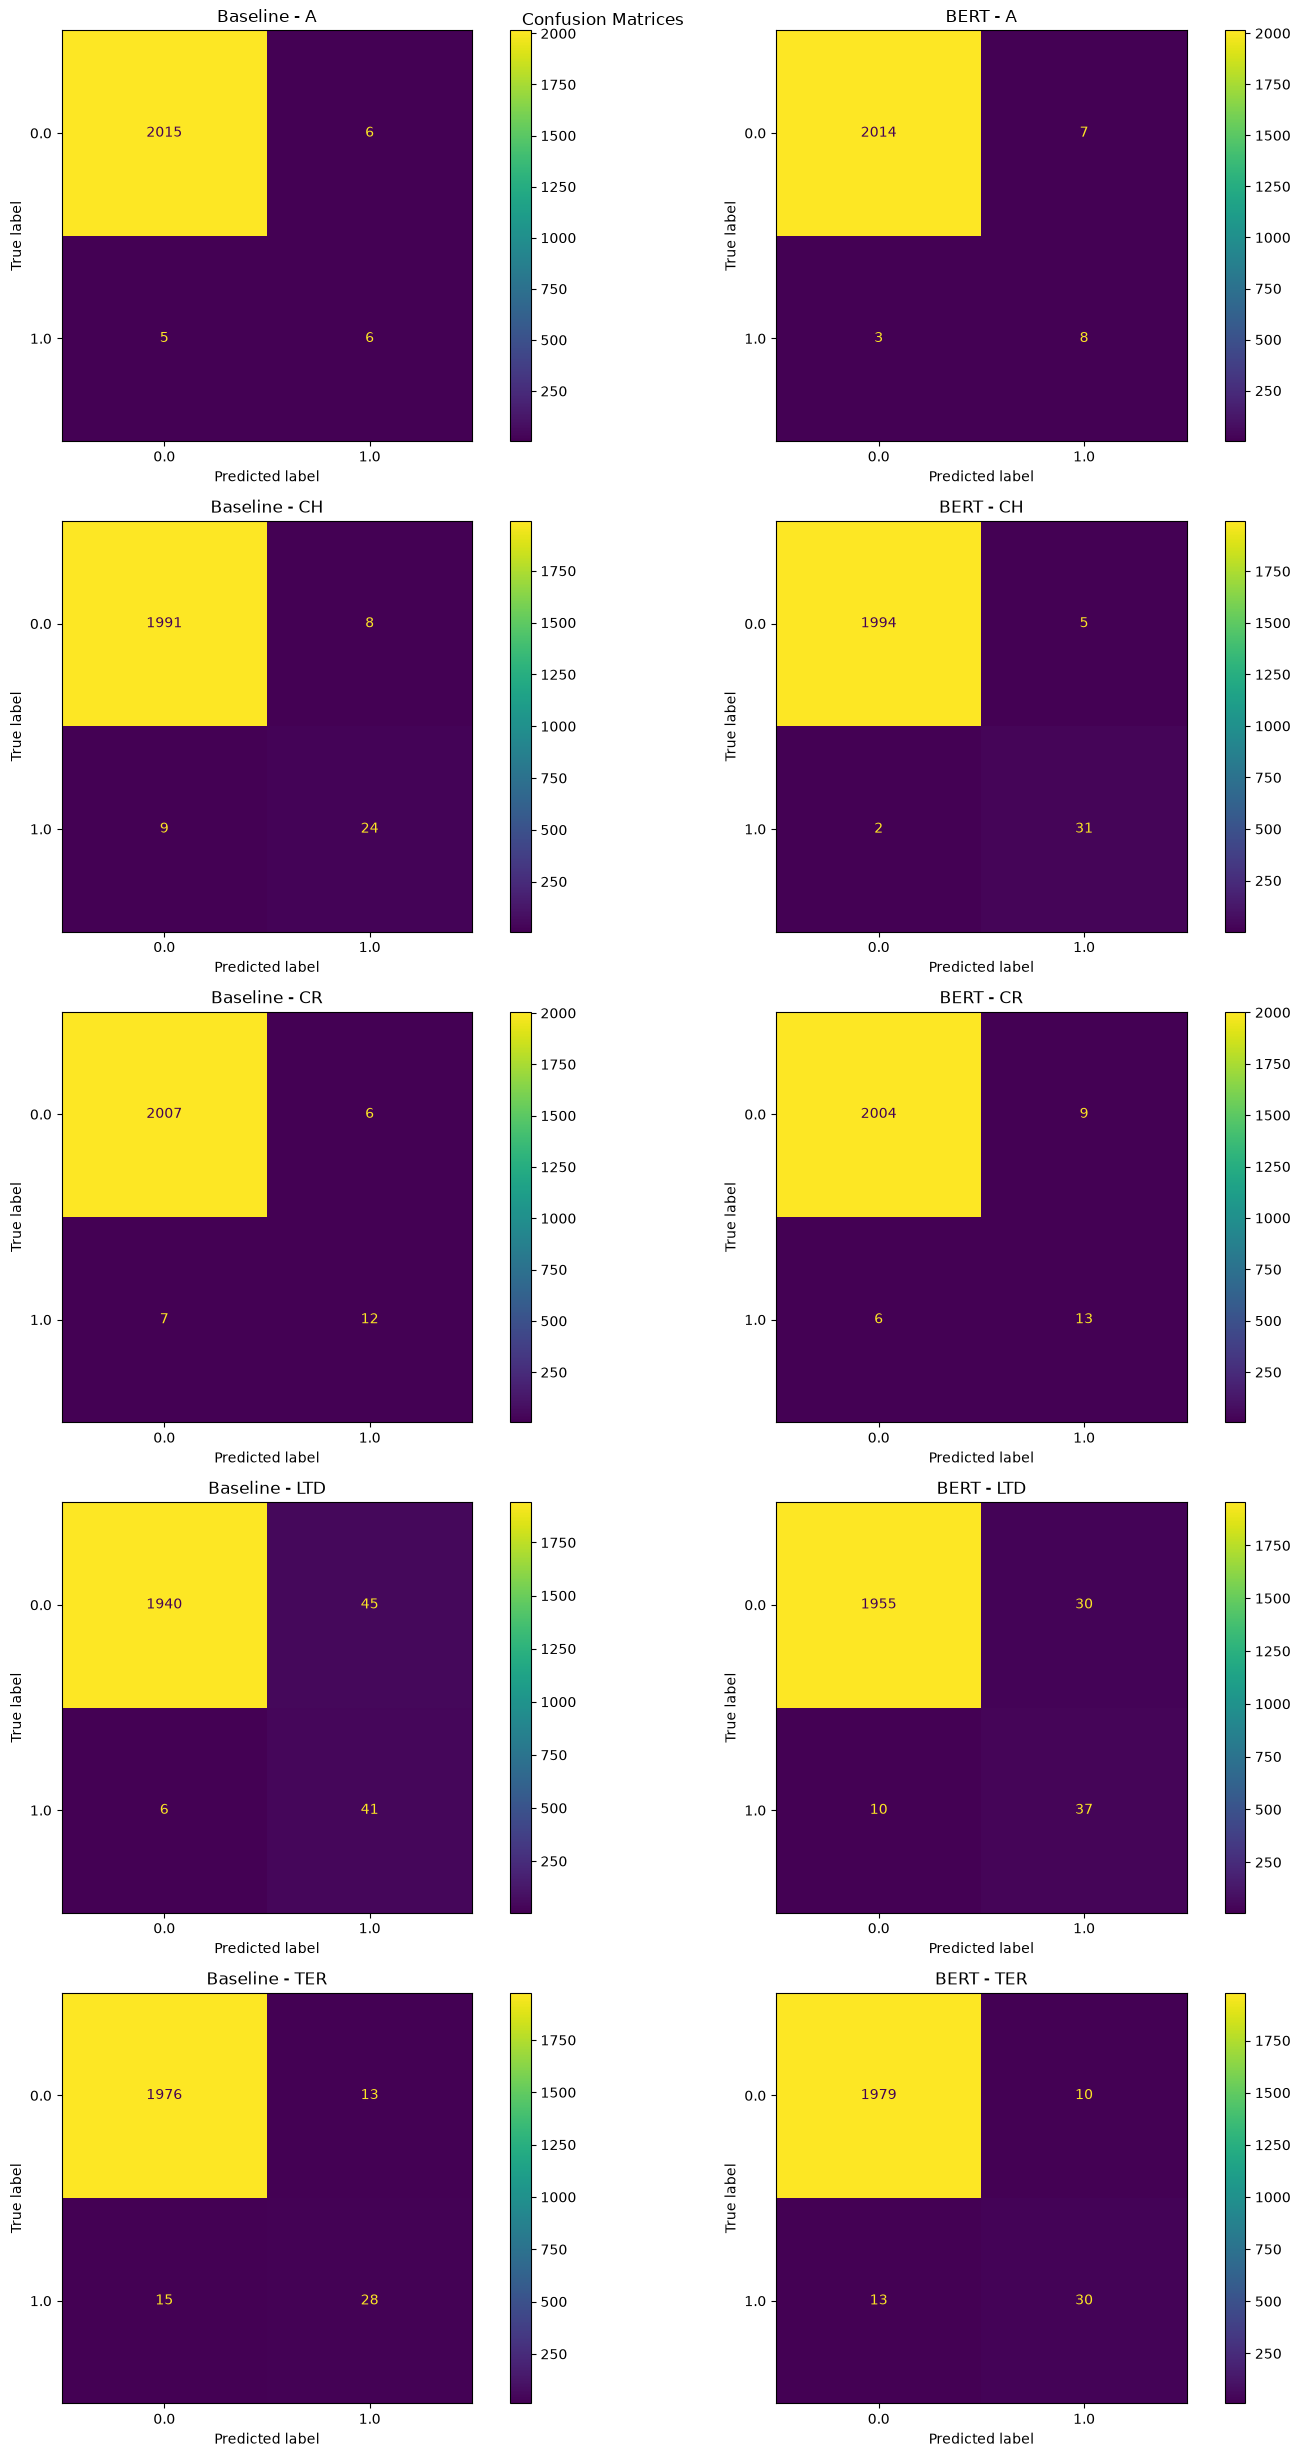

In [118]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

baseline = runs['Baseline'][-1]
bert = all_runs['LEGAL-BERT'][-1]

baseline_pred = (baseline['test_probs'] >= baseline['thresholds']).astype(int)
bert_pred = (bert['test_probs'] >= bert['thresholds']).astype(int)

fig, axs = plt.subplots(len(label_cols), 2, figsize=(15, 25))
fig.suptitle('Confusion Matrices')
confusion_matrices = {}
confusion_matrices['baseline'] = {}
confusion_matrices['bert'] = {}
for i in range(len(label_cols)):
    lb = label_cols[i]
    axs[i,0].set_title("Baseline - " + lb)
    axs[i,1].set_title("BERT - " + lb)
    confusion_matrices['baseline'][lb] = confusion_matrix(y_true=y_test[:,i],y_pred=baseline_pred[:,i])
    ConfusionMatrixDisplay.from_predictions(y_true=y_test[:,i],y_pred=baseline_pred[:,i], ax=axs[i,0])
    confusion_matrices['bert'][lb] = confusion_matrix(y_true=y_test[:,i],y_pred=bert_pred[:,i])
    ConfusionMatrixDisplay.from_predictions(y_true=y_test[:,i],y_pred=bert_pred[:,i], ax=axs[i,1])

plt.tight_layout()
plt.show()

Due to the heavely imbalanced dataset, trashold tuning procedure results unstable, as reflected in the F1 score variance. The issue is particularry evident for class `A`, where the same number of correctly identified samples mathces the number of `False Positive` and `False Negative`, sugesting that the limited aviability of positive samples constraint the models generalisation. 

Another intresting cases is the `LTD` class, on which both models predicts a relatively hig number of false positive, in some case exceeding the number of true positive. In contrast, the results for class `CH` highlight the benefit of pretraining, with BERT achieving better performance on every class. 

Overall, the recall/precision plots above describe the gain arised using a fine tuned model. 


### Precision and Recall


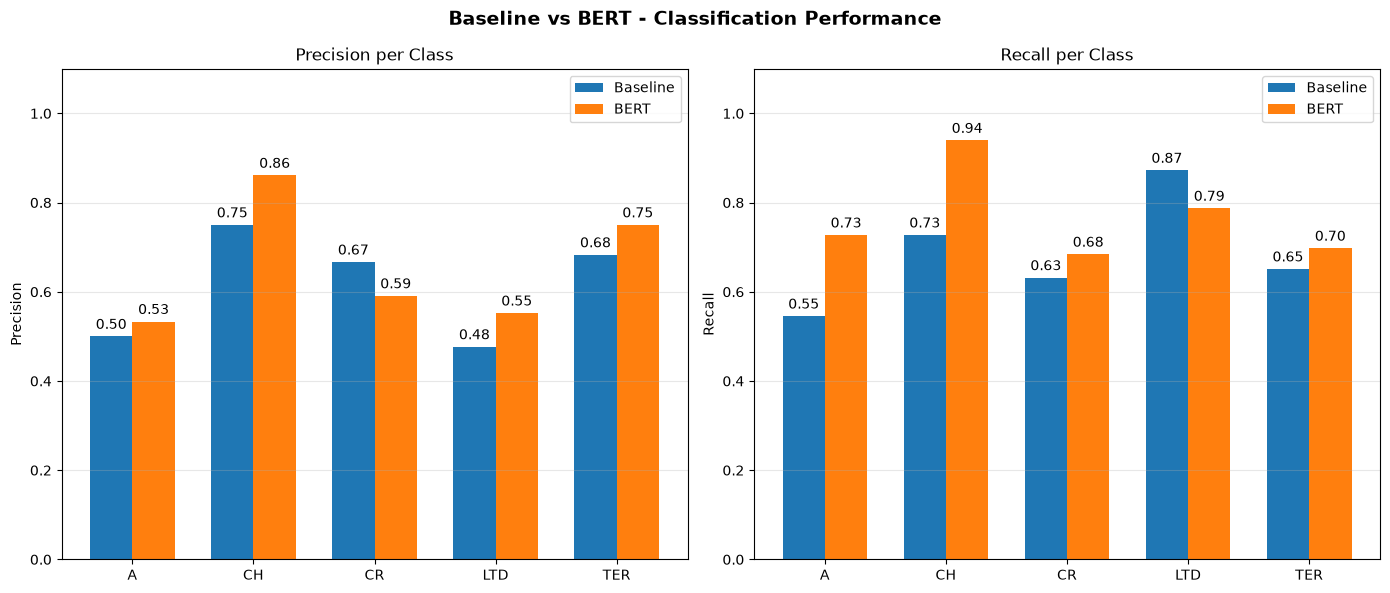

In [119]:
models = {
    "Baseline": baseline_pred,
    "BERT": bert_pred
}

metrics =  {
    'Precision' : precision_score,
    'Recall' : recall_score
}

fig, axs = plt.subplots(1,2, figsize=(14,6))

for ax, (metric, f) in zip(axs, metrics.items()):
    for i,(model,pred) in enumerate(models.items()):
        scores = [
            f(y_test[:,j], pred[:,j],zero_division=0)
            for j in range(len(label_cols))
        ]

        bars =  ax.bar(
            np.arange(len(label_cols)) + (i-0.5) * 0.35,
            scores,
            0.35,
            label=model
        )
        ax.bar_label(bars, fmt="%.2f", padding=3)

    ax.set_title(f"{metric} per Class")
    ax.set_xticks(np.arange(len(label_cols)))
    ax.set_xticklabels(label_cols)
    ax.set_ylim(0, 1.1)
    ax.set_ylabel(metric)
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Baseline vs BERT - Classification Performance",
             fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()

The histograms above show that the pretreined model generally outperforms the Baseline, although some class-specific trade-offs emerge.

The difference can be addressed to the different tokenization and embedding strategy used by the two models. Although  the vocabolary of the fine tuned model is approximately one-thirteenth  of the one constructed for the baseline, its **sub-words-based tokenization** allows it to represent many, previously unseen words, potentially reducing the occurrence of `<UNK>` tokens.

Furthermore, Bert uses a higher maximum sequence lenght that allows it to preserve more information on longer cluse, which are tipically positive.


### Substitution Heatmap and Co-occurence

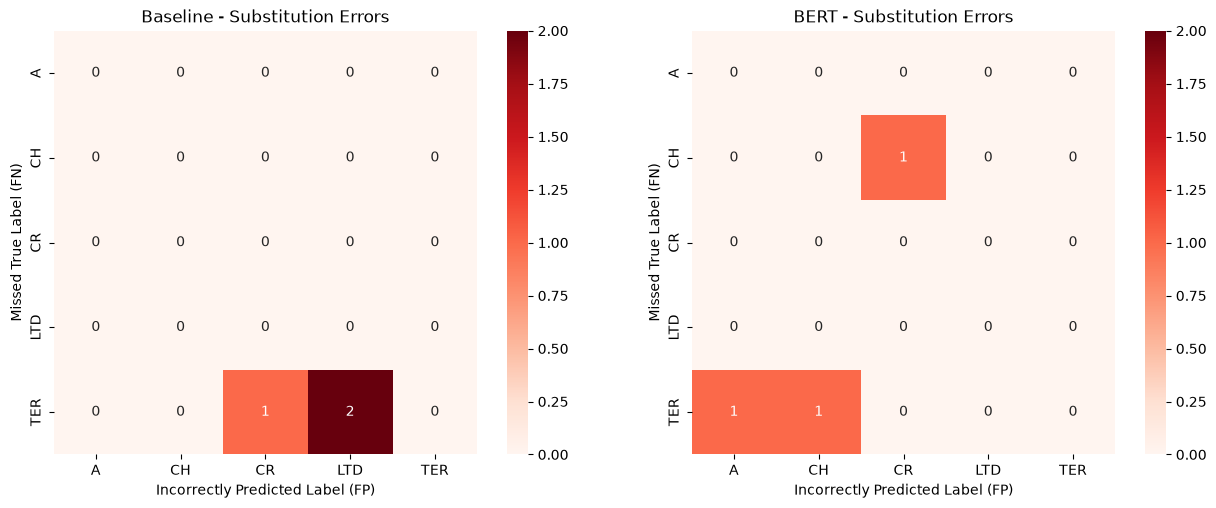

In [120]:
import seaborn as sns
def substitution_matrix(y_true, y_pred):
    y = np.asarray(y_true).astype(int)
    p = np.asarray(y_pred).astype(int)

    fn = (y == 1) & (p == 0)
    fp = (y == 0) & (p == 1)

    mask = (fn.sum(axis=1) == 1) & (fp.sum(axis=1) == 1)
    return fn[mask].astype(int).T @ fp[mask].astype(int)


baseline_cm = substitution_matrix(y_test, baseline_pred)
bert_cm = substitution_matrix(y_test, bert_pred)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

vmax = max(baseline_cm.max(), bert_cm.max(), 1)

for ax, cm, name in zip(
    axes,
    [baseline_cm, bert_cm],
    ["Baseline", "BERT"]
):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Reds",
        xticklabels=label_cols,
        yticklabels=label_cols,
        vmin=0,
        vmax=vmax,
        square=True,
        ax=ax
    )

    ax.set_title(f"{name} - Substitution Errors")
    ax.set_xlabel("Incorrectly Predicted Label (FP)")
    ax.set_ylabel("Missed True Label (FN)")

plt.tight_layout()
plt.show()


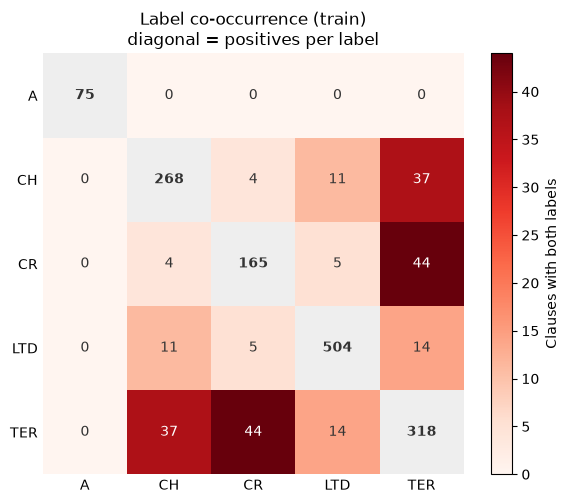

In [121]:
cooc = pd.DataFrame((y_train.T @ y_train).astype(int), index=label_cols, columns=label_cols)

off_diag = np.ma.masked_where(np.eye(len(label_cols), dtype=bool), cooc.to_numpy())
cmap = plt.get_cmap('Reds').copy()
cmap.set_bad('#eeeeee')

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(off_diag, cmap=cmap, vmin=0)

for i in range(len(label_cols)):
    for j in range(len(label_cols)):
        value = cooc.iat[i, j]
        dark_cell = i != j and value > off_diag.max() / 2
        ax.text(j, i, value, ha='center', va='center', fontsize=10,
                color='white' if dark_cell else '#333333', fontweight='bold' if i == j else 'normal')

ax.set_xticks(range(len(label_cols)), label_cols)
ax.set_yticks(range(len(label_cols)), label_cols)
ax.set_title('Label co-occurrence (train)\ndiagonal = positives per label')
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, label='Clauses with both labels')
fig.tight_layout()
plt.show()

The Heatmap shows where two classes are substituted that can be often reconducted to semantic overlaps and co-occurence frequency. Since both model made only five substitution in total, each is broke down below with a possible explanation for the confusion. 
**The baseline model** 
- it confuse one `TER` clause for a `CR` clause, while i mismatched twice a `TER` for a `LTD`:
    - The relationship between *Unilateral Termination* and *Limitation of Liability* may be help explain the first error. The co-occurence analysis highlights that the `CR-TER` is the most frequent combination, with but almost one-fourth of `CR` samples also belonging to the `TER` class. This substantial overlapping suggests that the two categories may share Lingustical or contextual features. However, the absence substitutions in the opposite direction (CR $\rightarrow$ TER) weaken such hypotesis. An alternative explanation may lie in the distribution of the `TER` samples within the dataset, as more almost a third of the samples belonging to the class also carry other label, potentially making it more difficult for the model to learn the distinctive feature of the class. Consequentlly, the models may associate feature shared across multiple categories to `CR`, leading to incrrect prediction like the one in exam.
    - A possible semantic relationship may be also identified between *Limitation of liability* and  *Unilateral Termination*, as both may involve contractual provision limiting the user or defining the provider's responsability, a cpnsiderable overlap of the linguistical feature that characterise is therefore plausible, but has not been tested. Nevertheless, this assumption remains purely speculative. 

**The fine tuned model BERT**: 
- BERT also produces three isolated label substitutions, but involving different category pairs.
    - The substitution of `TER` with the class `A` (*arbitration*) is particullary intresting because these categories are conceptually distinct and never co-occur in the dataset. This may highlight didifficulty in distinguish certian clause formulation.
    - the substitution between *unbilateral change* and *unilateral termination* can be reconduced to their potential semantic similarity, as both categories concern contractual provision that enables the provider to unilaterally modify aspects of the agreement. 
    - the last swap involves `CH` and `CR`, that co-occur only four times in training. It is plausible to thikn that their semantical features are not really similar due to the nature of the two categories. there is not enaugh evidence for any strong conclusion as it is an isolated case and the two classes have low correlation. It must be anyway noted the storng co-correlation of the two categoies with `TER`, such relationship remains anyway a mere speculation with no support.

Overall, the analysis highlights a potential generalisation difficultty, particullary accentuated for categories with limited positive samples. 


### OOV count

In [122]:
unk_mask = test_set['token_ids'].apply(
    lambda ids: UNK_IDX  in ids 
).to_numpy()

positive_mask = (y_test.sum(axis=1) > 0)
positive_unk_mask = unk_mask & positive_mask

correct_mask = (baseline_pred == y_test).all(axis=1)

n_unk = sum(
    ids.count(UNK_IDX) for ids in test_set['token_ids']
)

n_unk_samples = unk_mask.sum()
n_pos_unk = (unk_mask & positive_mask).sum()

positive_unk_error_rate = (
    100 * (~correct_mask[positive_unk_mask]).mean()
    if positive_unk_mask.sum() > 0 else 0
)

oov_ds = pd.DataFrame({
    'Metric': [
        'Number of UNK tokens',
        'Samples containing UNK',
        'Positive samples containing UNK',
        'error rate on positive samples (%)'
    ],
    'Value': [
        n_unk,
        n_unk_samples,
        n_pos_unk,
        round(positive_unk_error_rate, 2)
    ]
})

display(oov_ds)

,Metric,Value
0,Number of UNK tokens,552.00
1,Samples containing UNK,400.00
2,Positive samples containing UNK,35.00
3,error rate on positive samples (%),31.43


One of the limitation of the Baseline model is that it repleaces every unknown word with the special token`<UNK>`, resultin in 552 unseen words, among 400 different clause of the test split, collapsed into the same token. The error rate among these clasue is approximately 31.43%, sugesting that the loss of lexilcal information could potentially affect the model capacity to capture relevant semantic features. 

The advantage of the tokenization method of BERT is it sub-word appreach, by which he can in some degree understand words similiar to known ones that have however never been seen, dropping the number of OOV to only 9 in six sample. the great gap between the two models directly influences the higher preformance obtained by the finetuned BERT as less information is lost 

### Semantic Distribution

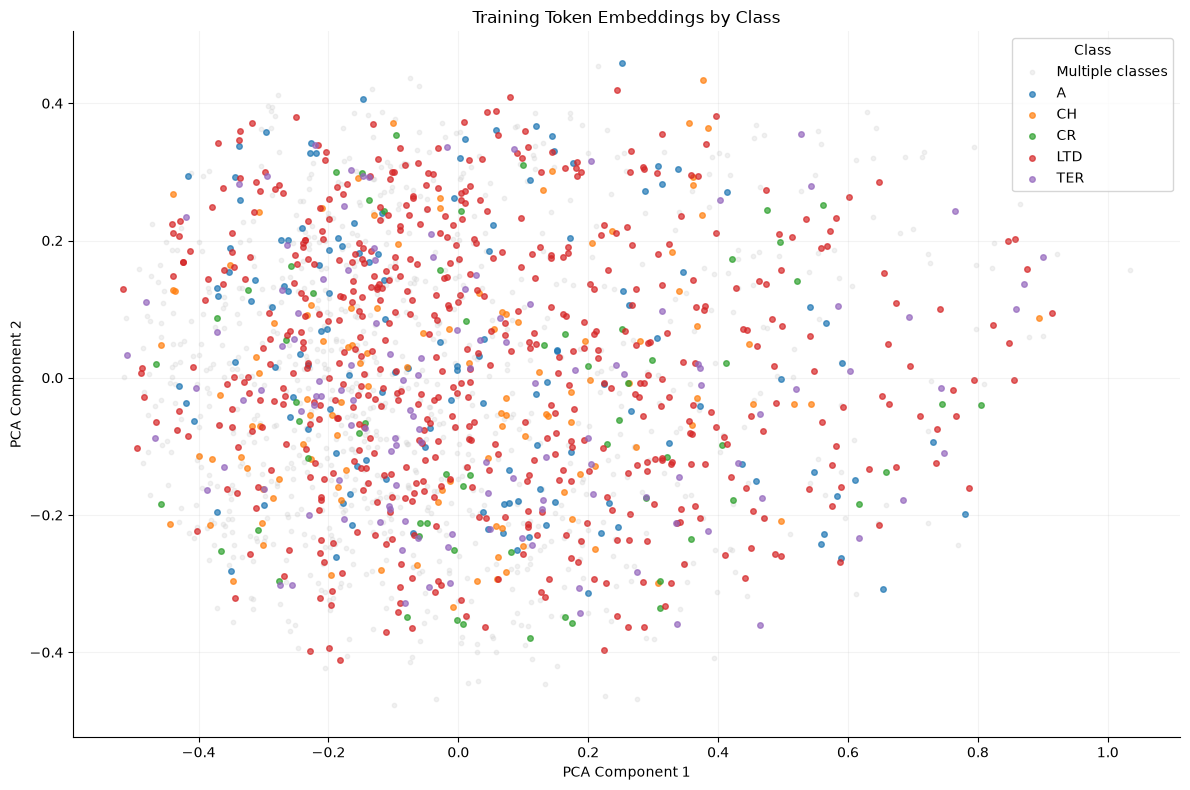

Tokens visualized: 1917
Explained variance: 15.53%


In [123]:
from collections import Counter, defaultdict
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize

MIN_DOC_FREQ = 2
MAX_TOKENS = None  # None = all eligible tokens
RANDOM_STATE = 42

doc_freq = Counter()
token_classes = defaultdict(set)

for _, row in training_set.iterrows():
    tokens = set(row['clean_text'].split())
    pos_labels = [
        label for label in label_cols
        if row[label] == 1
    ]

    for t in tokens:
        doc_freq[t] += 1
        token_classes[t].update(pos_labels)

selected_tokens = [
    t for t, classes in token_classes.items()
    if(
        1 <= len(classes) < len(label_cols)
        and doc_freq[t] >= MIN_DOC_FREQ
        and t in word_to_idx
    )
]

selected_tokens = sorted(selected_tokens, key=lambda t: (-doc_freq[t], t))

if MAX_TOKENS is not None:
    selected_tokens = selected_tokens[:MAX_TOKENS]


X = np.stack([
    embedding_matrix[word_to_idx[t]]
    for t in selected_tokens
])

X = normalize(X)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca.fit_transform(X)




fig, ax = plt.subplots(figsize=(12, 8))

colors = {
    label: plt.get_cmap('tab10')(i)
    for i, label in enumerate(label_cols)
}

# Multi-class tokens (grey)
multi_mask = np.array([
    len(token_classes[t]) > 1
    for t in selected_tokens
])

ax.scatter(
    X_2d[multi_mask, 0],
    X_2d[multi_mask, 1],
    color='lightgray',
    s=10,
    alpha=0.3,
    label='Multiple classes'
)

for label in label_cols:
    mask = np.array([
        token_classes[t] == {label}
        for t in selected_tokens
    ])

    ax.scatter(
        X_2d[mask, 0],
        X_2d[mask, 1],
        color=colors[label],
        s=16,
        alpha=0.7,
        label=label
    )

ax.set_title('Training Token Embeddings by Class')
ax.set_xlabel('PCA Component 1')
ax.set_ylabel('PCA Component 2')
ax.legend(title='Class')
ax.grid(alpha=0.15)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

print(f"Tokens visualized: {len(selected_tokens)}")
print(f"Explained variance: {pca.explained_variance_ratio_.sum():.2%}")

The scatter plot above represent the embedding's PCA projection of the unique token that characterise a category. there are also reported in gray multi-classes tokens. As one could notice, there is a strong overlap in the token distribution inside the PCA space, which would suggest that there isn't a clear bidimensional organization based on the categories. The PCA projection alone dose not prove that there aren't distinct division in higher dimensions, but provides a usefull view of problems highlighet above.

The graph highlight how the `LTD` token distribution spreds across the region. This is coherent with the results showed in the confusion matrix, in which the Baseline classifier produced a considerable number of FP, which suggest a difficulty in isolationg `LTD` clauses from others

In order to obtain a better representation of the token distribution follow the study oi the **inter-class cosine similarity** and **intra-class cosine similarity**

,Metric,Value
0,Mean intra-class similarity,0.1813
1,Mean inter-class similarity,0.1661
2,Difference (intra - inter),0.0152


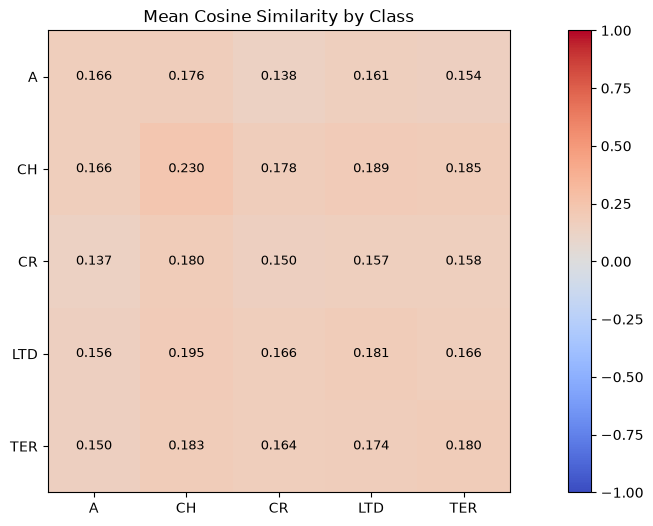

In [124]:
MAX_TOKENS_PER_CLASS = 500
MAX_PAIRS = 2000

rng = np.random.default_rng(RANDOM_STATE)

n_classes = len(label_cols)

similarity_matrix = np.full((n_classes,n_classes), np.nan)



class_embeddings = {}
class_tokens = {}

for label in label_cols:
    class_tokens[label] = sorted(
        [
            token for token, classes in token_classes.items()
            if (
                classes == {label}
                and doc_freq[token] >= MIN_DOC_FREQ
                and token in word_to_idx
            )
        ],
        key=lambda t: (-doc_freq[t], t)
    )[:MAX_TOKENS_PER_CLASS]

for label in label_cols:
    tokens = class_tokens[label]

    if tokens:
        X = np.stack([
            embedding_matrix[word_to_idx[t]]
            for t in tokens
        ])

        # Exclude zero vectors
        valid = np.linalg.norm(X, axis=1) > 0
        X = normalize(X[valid])

        class_embeddings[label] = X
        class_tokens[label] = [
            t for t, keep in zip(tokens, valid) if keep
        ]
    else:
        class_embeddings[label] = np.empty(
            (0, embedding_matrix.shape[1])
        )

scores = {}

scores['intra scores'] = []
scores['inter scores'] = []


for i, a in enumerate(label_cols):
    A = class_embeddings[a]
    for j,b in enumerate(label_cols):
        B = class_embeddings[b]

        if len(A) * len(B) == 0: continue

        if i == j and len(A) < 2: continue

        n_pairs = MAX_PAIRS

        idx_a = rng.integers(0,len(A), size=n_pairs) 
        idx_b = rng.integers(0,len(B),size=n_pairs)

        if i == j :
            same = idx_a == idx_b

            while same.any():
                idx_b[same] = rng.integers(0,len(B),size=same.sum())
                same = idx_a == idx_b

        score = np.sum(A[idx_a] * B[idx_b], axis=1)

        similarity_matrix[i,j] = score.mean()

        if i == j: 
            scores['intra scores'].extend(score)
        elif i < j:
            scores['inter scores'].extend(score)




fig, ax = plt.subplots(figsize=(15, 6))

im = ax.imshow(
    similarity_matrix,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(n_classes))
ax.set_yticks(range(n_classes))
ax.set_xticklabels(label_cols)
ax.set_yticklabels(label_cols)
ax.set_title('Mean Cosine Similarity by Class')

for i in range(n_classes):
    for j in range(n_classes):
        if np.isfinite(similarity_matrix[i, j]):
            ax.text(
                j, i,
                f'{similarity_matrix[i, j]:.3f}',
                ha='center',
                va='center',
                fontsize=9
            )

fig.colorbar(im, ax=ax, fraction=0.046)

# ---------------- SUMMARY ----------------
summary_df = pd.DataFrame({
    'Metric': [
        'Mean intra-class similarity',
        'Mean inter-class similarity',
        'Difference (intra - inter)'
    ],
    'Value': [
        np.mean(scores['intra scores']),
        np.mean(scores['inter scores']),
        np.mean(scores['intra scores']) - np.mean(scores['inter scores'])
  ]
})  

display(summary_df.round(4))

From the cosine similarity measure dose not emerges a clear separation among classes in the embedding space, supporting the sparse distribution idea arised from the PCA analysis.

Only `CH` exhibit a relativelly strong correlation. However, diagonla score are not systematically higher than the others, sugesting that the exclusive tokens of each class are semantically similar which makes the classification task considerablly harder, as the lessical similarity between words may not bring a concrete informative gain, pushing the model to rely on other cues. 

### Findings and Impact on Performance
The main problem encoutered was the absence of enaugh positive case for a complex case such the one under exam, as the positive caluse inside the trainig split cover only the 7.7% of the split, which made the classification task harder. The imbalance in the dataset can be seen in the confusion matrix above, in which most classes exhibit a high number of FP and FN. The less common class was *arbitration*, with only 75 samples in the training split which reflect the high level of FN and FP presented in teh confusion matrix. Obtain suitable precision bounderies in thsi settings has reveled to be challenging. 

The intrinsic multi-label characteristic of the problem adressed one more complication for the classification task as classes with high co-occurence may influence the model undertainding of the underlying semantic features, with the risk of confusing a feature of a class as a characteristic of another. 

For the Baseline model, major infrmation loss, in comperison with LEGAL-BERT finetuning, arise from the tokenization. The high number of `<UNK>` token in the test split, over 400 clause sugest a considerable loss of valuable information that has probablly impaired the performance, while the BERT approach has demonstrated to help the generalisation.

The input max length in training represent another factor information loss, The truncation is particullary heavy on the Baseline model, as it involve 97 clauses, of which 30 are positive. On the other hand, fine tuned model 

The cosine anlaysis revealed that the intitila GloVe emebedding dose not spontaniouslly organise tokens in gropus that can be associated to the category, which limits the informative gain of the token's lessical similarity

### Possible Solutions
Most of the problem discussed in the previous section can be addressed to two main characteristico of the dataset: **unbalanced class distribution** and **lessical overlap between class**.

The limited positive exemples contained in the dataset, combined with their unbalanced distribution, makes the classification task hard for both models. Considering the number of positive exemples present in the training split for the class `A` (75 in total), the models dose not have enaugh information to clearly define decision bounderies for said class. The solution adopted in the notebook was to oversample the few orignal ones. Experiments about the prediction of a non-oversempled `A` class show a moderate growth in precision. The solution is anyhow not scalable as it introduces the concrete risk of overfitting. The key finding in the same experiment was the benefits of using **class-weighted loss**, here as the `pos_weight` parameter, as it makes errors on positive clause more expensive. Mathematically:
$$
    L_c = - [w_c y_c \log \hat{y}_c + (1-y_c) \log(1- \hat{y}_c)] 
$$
so the error on positive clauses is multiplied by a parameter $w_c = \frac{N_c^{neg}}{N_c^{pos}}$. Without, having 92% of negative clause, the model would learn that always predicting a negative outcome would be cheaper, making recall drop toward zeero. the side effect is a decrease in precision due to the growing number of FP. Since the gradient of a single positive mistaken predictioction amplifies the gradient by a factor $w_c$ that can lead to noise, as it would be the equivalent of a higher learning rate ($lr \times w$) 
The experiment performed on the not oversampled split shows an intresting relation between the two: the weight associated to the class `A` in the experiment was `A_FACTOR` greater than the one in the Baseline reported studied in this notebook, which makaes it equivalent to duplicate positive samples, thus oversampling. The relationship between the two approach sugest that even pos_weight is exposed to overfitting. A soften formulation for the pos_weight (e.g. $w_c =\sqrt{\frac{N_c^{neg}}{N_c^{pos}}}$) could reduce the risk.  
Anther possible, yet more expensive solution would be **data agumentation**, to caputere the underling feature of the positive exemples, but it would require carefull examination of the new data, in order to preserve the original legal meaning of the exemple.

Regarding the threshold tuning, the high variability seen in different random seeds sugest that the selected threshold may be sensitive to the limited number of positive samples aviable.  

The substitution of unseen words with the `<UNK>` token generates a potential loss of lessical information that could benefit the Baseline performance. The comperison with the fine tuned modesl points toward the possible benefits of a subword-based tokenisation approach, as it would allow to represent previouslly unseen words through known subword units.

Finally, the substitution between some categories, along with the cosine similarity analysis, sugest that the categories share ambiguous and overlapping semantic features. Further analyses of the substituted samples and of the multi-label clauses amy provide insights on the lessical and semantical features that leed the model to confusion, and organise a possible data agumentation accordinglly

## Additional Experiments
Experiments run outside the main pipeline, mostly following the bonus suggestions of the assignment. None of them changes the configuration of Tasks 2 to 6.

- **Common method:** one factor changes at a time, and everything else follows Task 5 (LSTM models) or Task 6 (transformers): seeds 42, 1337 and 2026, best epoch on the validation macro F1 at threshold `0.5`, per-category thresholds tuned on the validation set. Scores are mean ± standard deviation over the seeds, and conclusions rely on the validation set only.
- **Code:** `Experiments/bonus_lstm.py`, `Experiments/legalbert_epochs.py` and copies of this notebook, with the runs saved in `Experiments/results/`. Rerunning Task 5 with `bonus_lstm.py` reproduces its validation scores (0.593 for the Baseline, 0.574 for the Stacked model, tuned thresholds).

### Sentence Encoding and Oversampling of `A`
- **Goal:** choose the sentence encoding of Task 4 and the oversampling factor of `A` of Task 5.
- **Method:** Baseline only, evaluated at threshold `0.5` without tuning. The oversampling was first compared with the final states, then repeated with the maximum.
- **Settings:** as in Task 5, except for the encoding (concatenation of the final forward and backward states, or element-wise maximum over the tokens) and `A_FACTOR` (1 or 4).
- **Results** (validation, threshold `0.5`):

| Encoding | `A_FACTOR` | Macro F1 | F1 `A` |
|---|---:|---:|---:|
| final states | 1 | 0.488 ± 0.023 | 0.299 |
| final states | 4 | 0.507 ± 0.015 | 0.357 |
| maximum | 1 | **0.547 ± 0.008** | 0.365 |
| **maximum (Tasks 4 and 5)** | 4 | 0.546 ± 0.006 | **0.401** |

- **Takeaway:** the maximum improves over the final states. With the maximum, `A` ×4 leaves the macro F1 unchanged and improves the F1 of `A`.

### Imbalance Strategies
- **Goal:** measure what each component of the Task 2b strategy adds (bonus: class weighting vs resampling vs threshold tuning).
- **Method:** both models are trained with eight combinations of a loss setting and a resampling setting; thresholds are tuned on every run.
- **Settings:** `pos_weight` absent, square root of $N_c^{neg} / N_c^{pos}$, or full; resampling absent, `A` ×4, or every positive clause ×3; the rest as in Task 5.
- **Results** (validation macro F1 unless stated):

| Strategy | Baseline, `0.5` | Baseline, tuned | Baseline F1 `A`, tuned | Baseline test, tuned | Stacked, tuned | Stacked F1 `A`, tuned |
|---|---:|---:|---:|---:|---:|---:|
| no mitigation | 0.583 | 0.610 ± 0.014 | 0.444 | 0.611 | 0.575 ± 0.009 | 0.433 |
| `A` ×4 | 0.586 | 0.605 ± 0.015 | 0.470 | 0.617 | 0.574 ± 0.017 | 0.419 |
| positives ×3 | 0.571 | 0.596 ± 0.026 | 0.415 | 0.597 | 0.582 ± 0.001 | 0.381 |
| `pos_weight`, square root | 0.577 | 0.595 ± 0.016 | 0.470 | 0.620 | 0.582 ± 0.023 | 0.434 |
| `A` ×4 + `pos_weight`, square root | 0.573 | 0.602 ± 0.009 | **0.515** | 0.644 | 0.588 ± 0.017 | **0.460** |
| `pos_weight` | 0.547 | 0.593 ± 0.010 | 0.437 | 0.620 | 0.572 ± 0.033 | 0.375 |
| **`A` ×4 + `pos_weight` (Task 2b)** | 0.546 | 0.593 ± 0.007 | 0.471 | **0.649** | 0.574 ± 0.016 | 0.440 |
| positives ×3 + `pos_weight` | 0.570 | 0.601 ± 0.006 | 0.500 | 0.624 | **0.589 ± 0.021** | 0.377 |

- **Takeaway:** with respect to Task 2b, every strategy leaves the tuned macro F1 unchanged on both models, within one standard deviation.

### Legal Word Embeddings
- **Goal:** check whether static embeddings trained on legal text help the LSTM models (bonus: swap GloVe for legal word embeddings).
- **Method:** GloVe is replaced by Law2Vec in the embedding matrix of both models.
- **Settings:** Law2Vec, 100 dimensions, 169,439 words, trained on legislation; every digit replaced with `D` in all splits, as in Law2Vec training; OOV handling as in Task 3; the rest as in Task 5.
- **Results:**

| | GloVe | Law2Vec |
|---|---:|---:|
| Train tokens added to the vocabulary (types / occurrences) | 18.5% / 1.1% | 21.9% / 3.1% |
| `<UNK>` occurrences in validation / test | 0.6% / 0.8% | 1.3% / 1.3% |
| Baseline, validation, tuned | **0.593 ± 0.007** | 0.554 ± 0.013 |
| Stacked, validation, tuned | **0.574 ± 0.016** | 0.559 ± 0.015 |
| Baseline, test, tuned | **0.649** | 0.612 |

- **Takeaway:** Law2Vec worsens the macro F1 on both models.

### General-domain Transformer
- **Goal:** measure what legal pre-training adds (bonus: compare against a general-domain transformer).
- **Method:** LEGAL-BERT is replaced by `bert-base-uncased`, which has the same architecture and vocabulary size (30,522 WordPiece tokens).
- **Settings:** as in Task 6: `bert_text`, `BERT_MAX_LEN = 256`, learning rate `2e-5`, 4 epochs, `A` ×4 and `pos_weight`.
- **Results:**

| Model | Validation, `0.5` | Validation, tuned | Validation F1 `A`, tuned | Test, tuned |
|---|---:|---:|---:|---:|
| Baseline | 0.546 ± 0.006 | 0.593 ± 0.007 | 0.471 | 0.649 ± 0.014 |
| `bert-base-uncased` | 0.644 ± 0.020 | **0.669 ± 0.014** | 0.487 | 0.694 ± 0.002 |
| LEGAL-BERT | **0.646 ± 0.012** | 0.664 ± 0.008 | **0.496** | **0.704 ± 0.001** |

- **Takeaway:** `bert-base-uncased` performs the same as LEGAL-BERT.

### Other Checks
- **Goal:** test single choices of Tasks 3, 5 and 6.
- **Method and settings:** one change at a time with respect to the reference of the same model:
    - `MAX_LEN = 300` instead of 150 (Baseline);
    - 50 epochs instead of 20 (both LSTM models);
    - 8 epochs instead of 4 (LEGAL-BERT);
    - two-stage cascade: a Baseline with a single output detects unfair clauses, a second Baseline trained on positive clauses only assigns the categories, and the probability of a category is the product of the two outputs.
- **Results** (validation macro F1, tuned thresholds):

| Check | Reference | Variant |
|---|---:|---:|
| Baseline, `MAX_LEN = 300` | 0.593 ± 0.007 | 0.602 ± 0.010 |
| Baseline, 50 epochs | 0.593 ± 0.007 | 0.592 ± 0.009 |
| Stacked, 50 epochs | 0.574 ± 0.016 | 0.572 ± 0.014 |
| LEGAL-BERT, 8 epochs | 0.664 ± 0.008 | 0.674 ± 0.004 |
| Baseline, cascade | 0.593 ± 0.007 | 0.594 ± 0.012 |

- **Takeaway:** `MAX_LEN = 300`, 50 epochs and the cascade leave the macro F1 unchanged; 8 epochs improve LEGAL-BERT.

### Overfitting Check
- **Goal:** verify the overfitting suggested by the learning curves of Task 5.
- **Method:** the Task 5 training of both LSTM models is repeated, logging after every epoch the validation loss (same weighted loss as training) and the macro F1 on the training clauses (without the oversampled copies, threshold `0.5`). The repeated runs have the same best epochs and validation scores as Task 5.
- **Settings:** as in Task 5.
- **Results** (mean over seeds):

| | Baseline | Stacked |
|---|---:|---:|
| Epoch of minimum validation loss | 2–3 | 2–3 |
| Validation loss, minimum / epoch 20 | 0.47 / 2.36 | 0.50 / 2.09 |
| Training macro F1 at the best epoch | 0.896 | 0.857 |
| Validation macro F1 at the best epoch | 0.546 | 0.547 |
| Validation macro F1 at epoch 20 | 0.532 | 0.491 |

- **Takeaway:** both models overfit: the validation loss grows from epoch 3 while the training loss keeps falling, and at the best epoch the training macro F1 exceeds the validation one by about 0.3. The Stacked model loses more validation F1 after its best epoch.